In [1]:
# Cell 1 — Configuration and environment setup

from pathlib import Path
import json
import random
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional PyTorch setup
try:
    import torch

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"PyTorch device: {DEVICE}")

    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
except ImportError:
    torch = None
    DEVICE = "cpu"
    print("PyTorch is not available; using CPU.")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

if torch is not None:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

# Project directories
PROJECT_ROOT = Path("/home/afanali/wcnc_project")

RESULTS_DIR = PROJECT_ROOT / "improved_experiment_v2" / "results"
FIGURES_DIR = PROJECT_ROOT / "improved_experiment_v2" / "figures_three_agents_robust"
REPORT_DIR = PROJECT_ROOT / "improved_experiment_v2" / "robust_three_agent_results"

# Create output directories
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Experiment configuration
NUM_FOLDS = 6
NUM_GNBS = 5
NUM_FORECAST_MODELS = 5

FORECAST_MODELS = [
    "persistence",
    "deterministic",
    "independent",
    "joint",
    "hurdle_joint",
]

# Policy configuration
DEFAULT_TTT_K = 2
DEFAULT_HANDOVER_COST_DB = 2.0
DEFAULT_FAILURE_PENALTY_DB = 2.0
DEFAULT_UNCERTAINTY_WEIGHT = 1.0

# Basic checks
assert PROJECT_ROOT.exists(), f"Project root not found: {PROJECT_ROOT}"
assert RESULTS_DIR.exists(), f"Results directory not found: {RESULTS_DIR}"

print(f"Project root: {PROJECT_ROOT}")
print(f"Results directory: {RESULTS_DIR}")
print(f"Figures will be saved to: {FIGURES_DIR}")
print(f"Reports will be saved to: {REPORT_DIR}")
print(f"Forecasting models: {FORECAST_MODELS}")
print(f"Number of LOTO folds: {NUM_FOLDS}")

PyTorch device: cuda
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Project root: /home/afanali/wcnc_project
Results directory: /home/afanali/wcnc_project/improved_experiment_v2/results
Figures will be saved to: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust
Reports will be saved to: /home/afanali/wcnc_project/improved_experiment_v2/robust_three_agent_results
Forecasting models: ['persistence', 'deterministic', 'independent', 'joint', 'hurdle_joint']
Number of LOTO folds: 6


In [2]:
# Cell 2 — Locate saved forecast and LOTO result files

from pathlib import Path

# Search recursively for previously generated data files
candidate_files = []

for pattern in ["*.pkl", "*.pickle", "*.joblib", "*.npz", "*.json"]:
    candidate_files.extend(RESULTS_DIR.rglob(pattern))

candidate_files = sorted(candidate_files)

print(f"Found {len(candidate_files)} result files:\n")

for file_path in candidate_files:
    size_mb = file_path.stat().st_size / (1024 ** 2)
    print(f"{file_path.relative_to(PROJECT_ROOT)}  |  {size_mb:.2f} MB")

# Likely files containing forecasts or LOTO fold outputs
keywords = [
    "forecast",
    "fold",
    "comparison",
    "runtime",
    "three_agent",
    "policy",
    "main",
]

likely_files = [
    path for path in candidate_files
    if any(key in path.name.lower() for key in keywords)
]

print("\nLikely experiment-input files:")
for file_path in likely_files:
    print(f"  {file_path.relative_to(PROJECT_ROOT)}")

if not candidate_files:
    print(
        "\nNo serialized result files were found. "
        "Check that the previous training/evaluation notebook has been executed."
    )

Found 12 result files:

improved_experiment_v2/results/agentic_policy_loto_comparison.json  |  0.01 MB
improved_experiment_v2/results/fold_0_summary_predictions.npz  |  0.39 MB
improved_experiment_v2/results/fold_1_summary_predictions.npz  |  0.38 MB
improved_experiment_v2/results/fold_2_summary_predictions.npz  |  0.38 MB
improved_experiment_v2/results/fold_3_summary_predictions.npz  |  0.39 MB
improved_experiment_v2/results/fold_4_summary_predictions.npz  |  0.38 MB
improved_experiment_v2/results/fold_5_summary_predictions.npz  |  0.38 MB
improved_experiment_v2/results/forecaster_loto_summary.json  |  0.01 MB
improved_experiment_v2/results/lidar_feature_ablation.json  |  0.01 MB
improved_experiment_v2/results/loto_fold_manifest.json  |  0.01 MB
improved_experiment_v2/results/policy_perfold_metrics.json  |  0.01 MB
improved_experiment_v2/results/revised_policy_report.json  |  0.04 MB

Likely experiment-input files:
  improved_experiment_v2/results/agentic_policy_loto_comparison.json
 

In [3]:
# Cell 3 — Load six LOTO folds and existing forecast outputs

import json
import numpy as np

# Load fold-level forecast files
fold_data = []

for fold_index in range(NUM_FOLDS):
    fold_path = RESULTS_DIR / f"fold_{fold_index}_summary_predictions.npz"

    if not fold_path.exists():
        raise FileNotFoundError(f"Missing fold file: {fold_path}")

    with np.load(fold_path, allow_pickle=True) as data:
        fold = {key: data[key] for key in data.files}

    fold_data.append(fold)

# Load supporting summaries
def load_json(path):
    with open(path, "r") as file:
        return json.load(file)

forecaster_summary = load_json(
    RESULTS_DIR / "forecaster_loto_summary.json"
)

policy_summary = load_json(
    RESULTS_DIR / "policy_perfold_metrics.json"
)

agentic_summary = load_json(
    RESULTS_DIR / "agentic_policy_loto_comparison.json"
)

fold_manifest = load_json(
    RESULTS_DIR / "loto_fold_manifest.json"
)

# Inspect the loaded data
print(f"Loaded {len(fold_data)} LOTO folds.")

print("\nFirst-fold keys:")
print(sorted(fold_data[0].keys()))

print("\nImportant array shapes:")
for key in [
    "test_target_db",
    "test_Yv",
    "test_observed_power_db",
]:
    if key in fold_data[0]:
        print(f"{key}: {fold_data[0][key].shape}")

print("\nAvailable summary files:")
print(f"Forecaster summary: {type(forecaster_summary).__name__}")
print(f"Policy summary:     {type(policy_summary).__name__}")
print(f"Agentic summary:    {type(agentic_summary).__name__}")
print(f"Fold manifest:      {type(fold_manifest).__name__}")

Loaded 6 LOTO folds.

First-fold keys:
['gnb_names', 'test_Yv', 'test_best', 'test_deterministic_mean_db', 'test_hurdle_joint_link_prob', 'test_hurdle_joint_mean_db', 'test_hurdle_joint_std_db', 'test_independent_mean_db', 'test_independent_std_db', 'test_joint_mean_db', 'test_joint_std_db', 'test_observed_power_db', 'test_persistence_mean_db', 'test_target_db', 'val_Yv', 'val_best', 'val_deterministic_mean_db', 'val_hurdle_joint_link_prob', 'val_hurdle_joint_mean_db', 'val_hurdle_joint_std_db', 'val_independent_mean_db', 'val_independent_std_db', 'val_joint_mean_db', 'val_joint_std_db', 'val_observed_power_db', 'val_persistence_mean_db', 'val_target_db']

Important array shapes:
test_target_db: (223, 6, 5)
test_Yv: (223, 6, 5)
test_observed_power_db: (223, 5)

Available summary files:
Forecaster summary: dict
Policy summary:     dict
Agentic summary:    dict
Fold manifest:      dict


In [4]:
# Cell 4 — Common forecast interface and evaluation helpers

from dataclasses import dataclass
from typing import Optional

MODEL_KEY_MAP = {
    "persistence": "persistence",
    "deterministic": "deterministic",
    "independent": "independent",
    "joint": "joint",
    "hurdle_joint": "hurdle_joint",
}

@dataclass
class ForecastBatch:
    mean_db: np.ndarray
    std_db: Optional[np.ndarray]
    validity_prob: Optional[np.ndarray]
    target_db: np.ndarray
    validity_mask: np.ndarray


def get_forecast_batch(fold, split, model_name):
    """
    Extract one model's forecast and target arrays.

    Returned shapes:
        mean_db:        [decision_epoch, horizon, gNB]
        std_db:         [decision_epoch, horizon, gNB] or None
        validity_prob:  [decision_epoch, horizon, gNB] or None
        target_db:      [decision_epoch, horizon, gNB]
        validity_mask:  [decision_epoch, horizon, gNB]
    """
    prefix = f"{split}_"

    mean_key = f"{prefix}{model_name}_mean_db"
    std_key = f"{prefix}{model_name}_std_db"
    prob_key = f"{prefix}{model_name}_link_prob"

    if mean_key not in fold:
        raise KeyError(f"Missing forecast key: {mean_key}")

    mean_db = np.asarray(fold[mean_key], dtype=np.float32)
    target_db = np.asarray(fold[f"{prefix}target_db"], dtype=np.float32)
    validity_mask = np.asarray(fold[f"{prefix}Yv"], dtype=np.float32)

    std_db = None
    if std_key in fold:
        std_db = np.asarray(fold[std_key], dtype=np.float32)

    validity_prob = None
    if prob_key in fold:
        validity_prob = np.asarray(fold[prob_key], dtype=np.float32)

    return ForecastBatch(
        mean_db=mean_db,
        std_db=std_db,
        validity_prob=validity_prob,
        target_db=target_db,
        validity_mask=validity_mask,
    )


def masked_mae_db(pred_db, target_db, validity_mask, eps=1e-8):
    """MAE computed only on valid ray-traced links."""
    error = np.abs(pred_db - target_db)
    mask = validity_mask.astype(bool)

    if not np.any(mask):
        return np.nan

    return float(error[mask].sum() / (mask.sum() + eps))


def first_step_mae_db(pred_db, target_db, validity_mask, eps=1e-8):
    """MAE for the first predicted future step."""
    return masked_mae_db(
        pred_db[:, 0, :],
        target_db[:, 0, :],
        validity_mask[:, 0, :],
        eps=eps,
    )


def validity_brier_score(prob, validity_mask, eps=1e-8):
    """Brier score for predicted link availability."""
    if prob is None:
        return np.nan

    prob = np.clip(prob, 0.0, 1.0)
    error = (prob - validity_mask) ** 2
    return float(np.mean(error))


def describe_fold(fold, fold_index=0):
    print(f"Fold {fold_index}")
    print(f"Number of decision epochs: {fold['test_target_db'].shape[0]}")
    print(f"Prediction horizon:       {fold['test_target_db'].shape[1]}")
    print(f"Number of candidate gNBs:  {fold['test_target_db'].shape[2]}")
    print(f"gNB names:                {list(fold['gnb_names'])}")


# Verify the interface on the first fold
describe_fold(fold_data[0], fold_index=0)

print("\nValidation forecast quality:")
for model_name in FORECAST_MODELS:
    batch = get_forecast_batch(fold_data[0], "val", model_name)

    mae = masked_mae_db(
        batch.mean_db,
        batch.target_db,
        batch.validity_mask,
    )

    brier = validity_brier_score(
        batch.validity_prob,
        batch.validity_mask,
    )

    print(
        f"{model_name:15s} | "
        f"masked MAE = {mae:7.3f} dB | "
        f"availability Brier = {brier:.4f}"
        if not np.isnan(brier)
        else
        f"{model_name:15s} | "
        f"masked MAE = {mae:7.3f} dB | "
        f"availability Brier = N/A"
    )

Fold 0
Number of decision epochs: 223
Prediction horizon:       6
Number of candidate gNBs:  5
gNB names:                [np.str_('gNB1_B59'), np.str_('gNB2_Building_44'), np.str_('gNB3_Building_54'), np.str_('gNB4_Building_29_Community_Center'), np.str_('gNB5_Building_617')]

Validation forecast quality:
persistence     | masked MAE =  18.445 dB | availability Brier = N/A
deterministic   | masked MAE =  14.359 dB | availability Brier = N/A
independent     | masked MAE =  15.316 dB | availability Brier = N/A
joint           | masked MAE =  16.713 dB | availability Brier = N/A
hurdle_joint    | masked MAE =   7.625 dB | availability Brier = 0.1378


In [5]:
# Cell 5 — Compute policy-aware validation statistics

def first_step_policy_statistics(batch, availability_threshold=0.5):
    """
    Evaluate how useful a forecast is for selecting the next target gNB.
    Statistics are computed only from validation data.
    """
    pred_db = batch.mean_db[:, 0, :].copy()
    true_db = batch.target_db[:, 0, :]
    true_valid = batch.validity_mask[:, 0, :].astype(bool)

    # True best usable gNB
    masked_true_db = np.where(true_valid, true_db, -np.inf)
    has_valid_target = np.any(true_valid, axis=1)

    true_best = np.argmax(masked_true_db, axis=1)

    # Use predicted availability only for the hurdle-aware model
    if batch.validity_prob is not None:
        pred_prob = np.clip(batch.validity_prob[:, 0, :], 0.0, 1.0)
        predicted_valid = pred_prob >= availability_threshold

        # If all candidates are rejected, fall back to the highest predicted power
        all_rejected = ~np.any(predicted_valid, axis=1)
        pred_score_db = pred_db.copy()
        pred_score_db[~predicted_valid] = -np.inf
        pred_score_db[all_rejected] = pred_db[all_rejected]

        predicted_best = np.argmax(pred_score_db, axis=1)
        predicted_validity = pred_prob[
            np.arange(len(predicted_best)),
            predicted_best,
        ]
    else:
        predicted_best = np.argmax(pred_db, axis=1)
        predicted_validity = np.ones(len(predicted_best))

    selected_real_validity = true_valid[
        np.arange(len(predicted_best)),
        predicted_best,
    ]

    selected_power = true_db[
        np.arange(len(predicted_best)),
        predicted_best,
    ]

    oracle_power = np.max(masked_true_db, axis=1)
    valid_gap = oracle_power - selected_power

    usable = has_valid_target & np.isfinite(valid_gap)

    return {
        "selection_accuracy": float(
            np.mean(predicted_best[usable] == true_best[usable])
        ) if np.any(usable) else np.nan,

        "selected_validity": float(
            np.mean(selected_real_validity[usable])
        ) if np.any(usable) else np.nan,

        "mean_oracle_gap_db": float(
            np.mean(valid_gap[usable])
        ) if np.any(usable) else np.nan,

        "predicted_availability_mean": float(
            np.mean(predicted_validity[usable])
        ) if np.any(usable) else np.nan,

        "usable_samples": int(np.sum(usable)),
        "total_samples": int(len(predicted_best)),
    }


# Compute validation statistics across all folds
validation_policy_stats = {}

for model_name in FORECAST_MODELS:
    model_stats = []

    for fold_index, fold in enumerate(fold_data):
        batch = get_forecast_batch(fold, "val", model_name)

        stats = first_step_policy_statistics(
            batch,
            availability_threshold=0.5,
        )
        stats["fold"] = fold_index
        model_stats.append(stats)

    validation_policy_stats[model_name] = model_stats


# Print aggregated validation statistics
print("Validation policy usefulness:")
print("-" * 78)

for model_name in FORECAST_MODELS:
    rows = validation_policy_stats[model_name]

    selection_accuracy = np.array(
        [row["selection_accuracy"] for row in rows],
        dtype=float,
    )
    selected_validity = np.array(
        [row["selected_validity"] for row in rows],
        dtype=float,
    )
    oracle_gap = np.array(
        [row["mean_oracle_gap_db"] for row in rows],
        dtype=float,
    )

    print(
        f"{model_name:15s} | "
        f"target accuracy = {np.nanmean(selection_accuracy):.3f} | "
        f"validity = {np.nanmean(selected_validity):.3f} | "
        f"oracle gap = {np.nanmean(oracle_gap):.3f} dB"
    )

Validation policy usefulness:
------------------------------------------------------------------------------
persistence     | target accuracy = 0.827 | validity = 0.969 | oracle gap = 4.319 dB
deterministic   | target accuracy = 0.815 | validity = 0.983 | oracle gap = 3.242 dB
independent     | target accuracy = 0.831 | validity = 0.984 | oracle gap = 2.873 dB
joint           | target accuracy = 0.813 | validity = 0.985 | oracle gap = 3.228 dB
hurdle_joint    | target accuracy = 0.827 | validity = 0.960 | oracle gap = 5.041 dB


In [6]:
# Cell 6 — Build policy-aware forecasting priors

# Aggregate validation statistics
prior_rows = []

for model_name in FORECAST_MODELS:
    rows = validation_policy_stats[model_name]

    mae_values = []
    selection_values = []
    validity_values = []
    gap_values = []

    for fold_index, fold in enumerate(fold_data):
        batch = get_forecast_batch(fold, "val", model_name)

        mae_values.append(
            masked_mae_db(
                batch.mean_db,
                batch.target_db,
                batch.validity_mask,
            )
        )

    for row in rows:
        selection_values.append(row["selection_accuracy"])
        validity_values.append(row["selected_validity"])
        gap_values.append(row["mean_oracle_gap_db"])

    prior_rows.append({
        "model": model_name,
        "mae_db": np.nanmean(mae_values),
        "selection_accuracy": np.nanmean(selection_values),
        "selected_validity": np.nanmean(validity_values),
        "oracle_gap_db": np.nanmean(gap_values),
    })

policy_prior_df = pd.DataFrame(prior_rows)


def minmax_good(values, lower_is_better=False):
    """
    Normalize values to [0, 1], where larger means better.
    """
    values = np.asarray(values, dtype=float)
    v_min = np.nanmin(values)
    v_max = np.nanmax(values)

    if np.isclose(v_max, v_min):
        score = np.ones_like(values)
    else:
        score = (values - v_min) / (v_max - v_min)

    if lower_is_better:
        score = 1.0 - score

    return score


# Normalize each validation criterion
policy_prior_df["mae_score"] = minmax_good(
    policy_prior_df["mae_db"],
    lower_is_better=True,
)

policy_prior_df["selection_score"] = minmax_good(
    policy_prior_df["selection_accuracy"],
    lower_is_better=False,
)

policy_prior_df["validity_score"] = minmax_good(
    policy_prior_df["selected_validity"],
    lower_is_better=False,
)

policy_prior_df["gap_score"] = minmax_good(
    policy_prior_df["oracle_gap_db"],
    lower_is_better=True,
)

# Balanced policy-aware score.
# The score intentionally prevents masked MAE from dominating target selection.
POLICY_SCORE_WEIGHTS = {
    "mae_score": 0.20,
    "selection_score": 0.30,
    "validity_score": 0.25,
    "gap_score": 0.25,
}

policy_prior_df["policy_score"] = sum(
    weight * policy_prior_df[criterion]
    for criterion, weight in POLICY_SCORE_WEIGHTS.items()
)

policy_prior_df = policy_prior_df.sort_values(
    "policy_score",
    ascending=False,
).reset_index(drop=True)

print("Policy-aware validation priors:")
display(
    policy_prior_df[
        [
            "model",
            "mae_db",
            "selection_accuracy",
            "selected_validity",
            "oracle_gap_db",
            "policy_score",
        ]
    ].round(4)
)

print("\nPreferred model according to policy-aware validation:")
print(policy_prior_df.iloc[0]["model"])

Policy-aware validation priors:


,model,mae_db,selection_accuracy,selected_validity,oracle_gap_db,policy_score
0,independent,15.8920,0.8312,0.9843,2.8726,0.8396
1,deterministic,14.4269,0.8154,0.9827,3.2420,0.5456
2,joint,16.1291,0.8132,0.9850,3.2276,0.5019
3,hurdle_joint,7.4846,0.8274,0.9602,5.0409,0.4371
4,persistence,18.4857,0.8267,0.9692,4.3188,0.3993



Preferred model according to policy-aware validation:
independent


In [7]:
# Cell 7 — Policy-aware Forecasting Agent

class PolicyAwareForecastingAgent:
    """
    Selects the forecaster using:
      1. Validation-based policy usefulness
      2. Recent causal forecasting reliability
      3. Predictive uncertainty
      4. Predicted link-availability confidence
    """

    def __init__(
        self,
        policy_prior_df,
        models,
        uncertainty_weight=0.15,
        availability_weight=0.15,
        reliability_weight=0.25,
    ):
        self.models = list(models)

        self.prior_scores = {
            row["model"]: float(row["policy_score"])
            for _, row in policy_prior_df.iterrows()
        }

        self.uncertainty_weight = uncertainty_weight
        self.availability_weight = availability_weight
        self.reliability_weight = reliability_weight

        self.recent_errors_db = {
            model: [] for model in self.models
        }

        self.selection_history = []

    def reset(self):
        self.recent_errors_db = {
            model: [] for model in self.models
        }
        self.selection_history = []

    def update_feedback(
        self,
        model_name,
        predicted_db,
        observed_db,
        observed_validity=None,
        max_history=20,
    ):
        """
        Update causal model reliability after the next observation becomes
        available. The current observation is never used before prediction.
        """
        predicted_db = np.asarray(predicted_db).reshape(-1)
        observed_db = np.asarray(observed_db).reshape(-1)

        valid = np.isfinite(predicted_db) & np.isfinite(observed_db)

        if observed_validity is not None:
            observed_validity = np.asarray(observed_validity).reshape(-1)
            valid = valid & observed_validity.astype(bool)

        if np.any(valid):
            error_db = float(
                np.mean(np.abs(predicted_db[valid] - observed_db[valid]))
            )

            self.recent_errors_db[model_name].append(error_db)
            self.recent_errors_db[model_name] = (
                self.recent_errors_db[model_name][-max_history:]
            )

    def _reliability_score(self, model_name):
        errors = self.recent_errors_db[model_name]

        if not errors:
            return 1.0

        mean_error = float(np.mean(errors))

        # Smooth conversion from recent MAE to a [0, 1] reliability score
        return float(np.exp(-mean_error / 10.0))

    @staticmethod
    def _normalize(values, larger_is_better=True):
        values = np.asarray(values, dtype=float)

        if np.allclose(values.max(), values.min()):
            return np.ones_like(values)

        normalized = (values - values.min()) / (
            values.max() - values.min()
        )

        if not larger_is_better:
            normalized = 1.0 - normalized

        return normalized

    def select(self, forecast_batches, decision_epoch=0):
        """
        forecast_batches:
            Dictionary mapping model names to ForecastBatch objects.
            Each batch should contain one or more decision epochs.

        Returns:
            selected model, model scores, and diagnostic information.
        """
        model_uncertainty = {}
        model_availability = {}
        model_predicted_target = {}

        for model_name in self.models:
            batch = forecast_batches[model_name]

            mean_db = batch.mean_db[0, 0, :]
            model_predicted_target[model_name] = int(np.argmax(mean_db))

            if batch.std_db is not None:
                uncertainty = float(
                    np.mean(batch.std_db[0, : min(2, batch.std_db.shape[1]), :])
                )
            else:
                uncertainty = 0.0

            model_uncertainty[model_name] = uncertainty

            if batch.validity_prob is not None:
                target_index = model_predicted_target[model_name]
                availability = float(
                    np.mean(
                        batch.validity_prob[
                            0,
                            : min(2, batch.validity_prob.shape[1]),
                            target_index,
                        ]
                    )
                )
            else:
                # No explicit availability head
                availability = 0.90

            model_availability[model_name] = availability

        uncertainty_values = np.array(
            [model_uncertainty[m] for m in self.models],
            dtype=float,
        )

        availability_values = np.array(
            [model_availability[m] for m in self.models],
            dtype=float,
        )

        uncertainty_scores = self._normalize(
            uncertainty_values,
            larger_is_better=False,
        )

        availability_scores = self._normalize(
            availability_values,
            larger_is_better=True,
        )

        total_scores = {}

        for index, model_name in enumerate(self.models):
            prior_score = self.prior_scores.get(model_name, 0.0)
            reliability_score = self._reliability_score(model_name)

            total_score = (
                0.60 * prior_score
                + self.reliability_weight * reliability_score
                + self.uncertainty_weight * uncertainty_scores[index]
                + self.availability_weight * availability_scores[index]
            )

            total_scores[model_name] = float(total_score)

        selected_model = max(
            total_scores,
            key=total_scores.get,
        )

        self.selection_history.append({
            "decision_epoch": int(decision_epoch),
            "selected_model": selected_model,
            "scores": total_scores.copy(),
        })

        return {
            "selected_model": selected_model,
            "scores": total_scores,
            "uncertainty": model_uncertainty,
            "availability": model_availability,
            "predicted_target": model_predicted_target,
        }


# Initialize the agent
forecasting_agent = PolicyAwareForecastingAgent(
    policy_prior_df=policy_prior_df,
    models=FORECAST_MODELS,
)

# Test the agent on the first test epoch of Fold 0
test_forecasts_fold0 = {
    model_name: get_forecast_batch(
        fold_data[0],
        "test",
        model_name,
    )
    for model_name in FORECAST_MODELS
}

first_epoch_forecasts = {
    model_name: ForecastBatch(
        mean_db=batch.mean_db[:1],
        std_db=None if batch.std_db is None else batch.std_db[:1],
        validity_prob=(
            None
            if batch.validity_prob is None
            else batch.validity_prob[:1]
        ),
        target_db=batch.target_db[:1],
        validity_mask=batch.validity_mask[:1],
    )
    for model_name, batch in test_forecasts_fold0.items()
}

forecasting_decision = forecasting_agent.select(
    first_epoch_forecasts,
    decision_epoch=0,
)

print("Forecasting Agent decision:")
print(f"Selected model: {forecasting_decision['selected_model']}")

print("\nModel scores:")
for model_name, score in sorted(
    forecasting_decision["scores"].items(),
    key=lambda item: item[1],
    reverse=True,
):
    print(f"{model_name:15s}: {score:.4f}")

Forecasting Agent decision:
Selected model: independent

Model scores:
independent    : 0.9043
deterministic  : 0.8773
persistence    : 0.7896
joint          : 0.7011
hurdle_joint   : 0.6338


In [8]:
# Cell 8 — Risk-aware Planning Agent with finite-horizon DP and TTT

class RiskAwarePlanningAgent:
    """
    Selects:
      - handover target
      - planning horizon
      - uncertainty weight
      - failure penalty
      - TTT persistence

    The planner evaluates candidate future target sequences using a
    finite-horizon dynamic-programming objective.
    """

    def __init__(
        self,
        horizon_options=(1, 2, 3, 4),
        beta_options=(0.25, 0.5, 1.0, 1.5),
        failure_penalty_options=(1.0, 2.0, 4.0),
        ttt_options=(1, 2, 3),
        handover_cost_db=2.0,
        reliability_penalty_db=2.0,
    ):
        self.horizon_options = tuple(horizon_options)
        self.beta_options = tuple(beta_options)
        self.failure_penalty_options = tuple(
            failure_penalty_options
        )
        self.ttt_options = tuple(ttt_options)

        self.handover_cost_db = float(handover_cost_db)
        self.reliability_penalty_db = float(
            reliability_penalty_db
        )

        self.plan_history = []

    @staticmethod
    def _get_uncertainty(batch, horizon):
        if batch.std_db is None:
            return np.zeros_like(batch.mean_db[0, :horizon, :])

        return np.nan_to_num(
            batch.std_db[0, :horizon, :],
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

    @staticmethod
    def _get_availability(batch, horizon):
        if batch.validity_prob is None:
            return np.ones_like(batch.mean_db[0, :horizon, :])

        return np.clip(
            np.nan_to_num(
                batch.validity_prob[0, :horizon, :],
                nan=0.0,
                posinf=1.0,
                neginf=0.0,
            ),
            0.0,
            1.0,
        )

    def _dynamic_programming_plan(
        self,
        batch,
        serving_index,
        reliability,
        horizon,
        beta,
        failure_penalty,
        ttt_k,
    ):
        mean_db = np.asarray(
            batch.mean_db[0, :horizon, :],
            dtype=float,
        )

        uncertainty_db = self._get_uncertainty(
            batch,
            horizon,
        )

        availability = self._get_availability(
            batch,
            horizon,
        )

        reliability = np.asarray(reliability, dtype=float)
        reliability = np.clip(reliability, 0.0, 1.0)

        # Risk-aware predicted utility
        utility = (
            mean_db
            - beta * uncertainty_db
            - failure_penalty * (1.0 - availability)
            - self.reliability_penalty_db
            * (1.0 - reliability[None, :])
        )

        num_steps, num_gnbs = utility.shape

        # Dynamic-programming tables
        dp = np.full(
            (num_steps, num_gnbs),
            -np.inf,
            dtype=float,
        )

        first_action = np.full(
            (num_steps, num_gnbs),
            serving_index,
            dtype=int,
        )

        # First future step: transition from current serving gNB
        for target_index in range(num_gnbs):
            switch_cost = (
                self.handover_cost_db
                if target_index != serving_index
                else 0.0
            )

            dp[0, target_index] = (
                utility[0, target_index]
                - switch_cost
            )

            first_action[0, target_index] = target_index

        # Future steps
        for step in range(1, num_steps):
            for target_index in range(num_gnbs):
                transition_values = np.empty(num_gnbs)

                for previous_index in range(num_gnbs):
                    switch_cost = (
                        self.handover_cost_db
                        if target_index != previous_index
                        else 0.0
                    )

                    transition_values[previous_index] = (
                        dp[step - 1, previous_index]
                        - switch_cost
                    )

                best_previous = int(
                    np.argmax(transition_values)
                )

                dp[step, target_index] = (
                    utility[step, target_index]
                    + transition_values[best_previous]
                )

                first_action[step, target_index] = (
                    first_action[
                        step - 1,
                        best_previous,
                    ]
                )

        # Select best terminal state
        terminal_index = int(np.argmax(dp[-1, :]))
        recommended_target = int(
            first_action[-1, terminal_index]
        )

        # Enforce TTT persistence on a proposed handover
        if recommended_target != serving_index:
            persistence_steps = min(ttt_k, num_steps)

            target_utility = utility[
                :persistence_steps,
                recommended_target,
            ]

            serving_utility = utility[
                :persistence_steps,
                serving_index,
            ]

            persistent = np.all(
                target_utility >= serving_utility
            )

            if not persistent:
                recommended_target = serving_index

        objective = float(
            dp[-1, terminal_index]
        )

        uncertainty_level = float(
            np.mean(uncertainty_db)
        )

        return {
            "recommended_target": recommended_target,
            "horizon": int(horizon),
            "beta": float(beta),
            "failure_penalty_db": float(failure_penalty),
            "ttt_k": int(ttt_k),
            "uncertainty_level": uncertainty_level,
            "objective": objective,
            "utility": utility,
        }

    def plan(
        self,
        batch,
        serving_index,
        reliability=None,
        decision_epoch=0,
    ):
        num_gnbs = batch.mean_db.shape[-1]

        if reliability is None:
            reliability = np.ones(num_gnbs)

        candidate_plans = []

        max_available_horizon = batch.mean_db.shape[1]

        for horizon in self.horizon_options:
            if horizon > max_available_horizon:
                continue

            for beta in self.beta_options:
                for failure_penalty in (
                    self.failure_penalty_options
                ):
                    for ttt_k in self.ttt_options:
                        plan = self._dynamic_programming_plan(
                            batch=batch,
                            serving_index=serving_index,
                            reliability=reliability,
                            horizon=horizon,
                            beta=beta,
                            failure_penalty=failure_penalty,
                            ttt_k=ttt_k,
                        )

                        candidate_plans.append(plan)

        if not candidate_plans:
            raise RuntimeError(
                "No valid planning configuration was found."
            )

        best_plan = max(
            candidate_plans,
            key=lambda plan: plan["objective"],
        )

        if best_plan["recommended_target"] == serving_index:
            action = "stay"
        else:
            action = "handover"

        best_plan["serving_index"] = int(serving_index)
        best_plan["action"] = action
        best_plan["decision_epoch"] = int(decision_epoch)

        self.plan_history.append(best_plan)

        return best_plan


# Initialize the Planning Agent
planning_agent = RiskAwarePlanningAgent(
    horizon_options=(1, 2, 3, 4),
    beta_options=(0.25, 0.5, 1.0, 1.5),
    failure_penalty_options=(1.0, 2.0, 4.0),
    ttt_options=(1, 2, 3),
    handover_cost_db=2.0,
    reliability_penalty_db=2.0,
)

# Test on Fold 0, first test epoch, using the selected forecaster
selected_model = forecasting_decision["selected_model"]
selected_batch = first_epoch_forecasts[selected_model]

initial_serving_index = 4
initial_reliability = np.ones(NUM_GNBS)

planning_decision = planning_agent.plan(
    batch=selected_batch,
    serving_index=initial_serving_index,
    reliability=initial_reliability,
    decision_epoch=0,
)

print("Planning Agent decision:")
for key in [
    "action",
    "recommended_target",
    "serving_index",
    "horizon",
    "beta",
    "failure_penalty_db",
    "ttt_k",
    "uncertainty_level",
    "objective",
]:
    print(f"{key:22s}: {planning_decision[key]}")

Planning Agent decision:
action                : stay
recommended_target    : 4
serving_index         : 4
horizon               : 1
beta                  : 0.25
failure_penalty_db    : 1.0
ttt_k                 : 1
uncertainty_level     : 35.219139099121094
objective             : -152.58126640319824


In [9]:
# Cell 9 — Adaptation Agent for reliability and risk updates

class AdaptationAgent:
    """
    Updates online control information using execution feedback:

      - per-gNB reliability
      - per-forecaster reliability
      - forecast weights
      - recent failure rate
      - switching pressure
      - planning risk multiplier
    """

    def __init__(
        self,
        models,
        num_gnbs,
        prior_scores=None,
        reliability_alpha=0.20,
        error_scale_db=10.0,
        softmax_temperature=0.20,
    ):
        self.models = list(models)
        self.num_gnbs = int(num_gnbs)

        self.reliability_alpha = float(
            reliability_alpha
        )
        self.error_scale_db = float(error_scale_db)
        self.softmax_temperature = float(
            softmax_temperature
        )

        self.gnb_reliability = np.ones(self.num_gnbs)
        self.model_reliability = {
            model: 1.0 for model in self.models
        }

        self.model_error_ema_db = {
            model: 0.0 for model in self.models
        }

        if prior_scores is None:
            prior_scores = {
                model: 1.0 for model in self.models
            }

        self.prior_scores = {
            model: float(prior_scores.get(model, 1.0))
            for model in self.models
        }

        self.forecast_weights = self._compute_forecast_weights()

        self.recent_failure_rate = 0.0
        self.recent_switching_pressure = 0.0
        self.update_history = []

    def reset(self):
        self.gnb_reliability = np.ones(self.num_gnbs)

        self.model_reliability = {
            model: 1.0 for model in self.models
        }

        self.model_error_ema_db = {
            model: 0.0 for model in self.models
        }

        self.forecast_weights = self._compute_forecast_weights()

        self.recent_failure_rate = 0.0
        self.recent_switching_pressure = 0.0
        self.update_history = []

    def _compute_forecast_weights(self):
        """
        Combine validation priors and online model reliability.
        """
        raw_scores = []

        for model in self.models:
            prior = max(self.prior_scores[model], 1e-6)
            reliability = max(
                self.model_reliability[model],
                1e-6,
            )

            raw_scores.append(
                np.log(prior) + np.log(reliability)
            )

        raw_scores = np.asarray(raw_scores)

        raw_scores = raw_scores / self.softmax_temperature
        raw_scores = raw_scores - np.max(raw_scores)

        weights = np.exp(raw_scores)
        weights = weights / np.sum(weights)

        return {
            model: float(weight)
            for model, weight in zip(
                self.models,
                weights,
            )
        }

    def update(
        self,
        predictions_by_model,
        observed_power_db,
        observed_validity,
        serving_index,
        selected_target,
        action,
    ):
        """
        Update the agent after the next realized observation is available.

        predictions_by_model:
            Dictionary of first-step predictions with shape [gNB].

        observed_power_db:
            Realized first-step path power with shape [gNB].

        observed_validity:
            Realized validity mask with shape [gNB].
        """
        observed_power_db = np.asarray(
            observed_power_db,
            dtype=float,
        ).reshape(-1)

        observed_validity = np.asarray(
            observed_validity,
            dtype=bool,
        ).reshape(-1)

        # Update model reliability using only realized valid links
        for model_name in self.models:
            prediction = np.asarray(
                predictions_by_model[model_name],
                dtype=float,
            ).reshape(-1)

            valid = (
                observed_validity
                & np.isfinite(prediction)
                & np.isfinite(observed_power_db)
            )

            if np.any(valid):
                error_db = float(
                    np.mean(
                        np.abs(
                            prediction[valid]
                            - observed_power_db[valid]
                        )
                    )
                )

                old_error = self.model_error_ema_db[
                    model_name
                ]

                new_error = (
                    (1.0 - self.reliability_alpha)
                    * old_error
                    + self.reliability_alpha
                    * error_db
                )

                self.model_error_ema_db[
                    model_name
                ] = new_error

                self.model_reliability[
                    model_name
                ] = float(
                    np.exp(
                        -new_error
                        / self.error_scale_db
                    )
                )

        # Update target-gNB reliability
        target_valid = bool(
            observed_validity[selected_target]
        )

        old_gnb_reliability = self.gnb_reliability[
            selected_target
        ]

        target_feedback = 1.0 if target_valid else 0.0

        self.gnb_reliability[
            selected_target
        ] = (
            (1.0 - self.reliability_alpha)
            * old_gnb_reliability
            + self.reliability_alpha
            * target_feedback
        )

        # Update failure and switching statistics
        is_handover = action == "handover"
        is_failure = is_handover and not target_valid

        self.recent_failure_rate = (
            (1.0 - self.reliability_alpha)
            * self.recent_failure_rate
            + self.reliability_alpha
            * float(is_failure)
        )

        self.recent_switching_pressure = (
            (1.0 - self.reliability_alpha)
            * self.recent_switching_pressure
            + self.reliability_alpha
            * float(is_handover)
        )

        # Recompute model weights after feedback
        self.forecast_weights = (
            self._compute_forecast_weights()
        )

        planning_risk_multiplier = (
            1.0
            + self.recent_failure_rate
            + 0.5
            * self.recent_switching_pressure
        )

        update_record = {
            "selected_target": int(selected_target),
            "target_valid": target_valid,
            "action": action,
            "failure": bool(is_failure),
            "failure_rate": self.recent_failure_rate,
            "switching_pressure": (
                self.recent_switching_pressure
            ),
            "planning_risk_multiplier": (
                planning_risk_multiplier
            ),
            "gnb_reliability": (
                self.gnb_reliability.copy()
            ),
            "model_reliability": (
                self.model_reliability.copy()
            ),
            "forecast_weights": (
                self.forecast_weights.copy()
            ),
        }

        self.update_history.append(update_record)

        return update_record


# Initialize the Adaptation Agent
prior_score_lookup = {
    row["model"]: float(row["policy_score"])
    for _, row in policy_prior_df.iterrows()
}

adaptation_agent = AdaptationAgent(
    models=FORECAST_MODELS,
    num_gnbs=NUM_GNBS,
    prior_scores=prior_score_lookup,
)

# Demonstration update using the first realized future step of Fold 0
predictions_by_model = {
    model_name: test_forecasts_fold0[
        model_name
    ].mean_db[0, 0, :]
    for model_name in FORECAST_MODELS
}

observed_power_db = fold_data[0][
    "test_target_db"
][0, 0, :]

observed_validity = fold_data[0][
    "test_Yv"
][0, 0, :]

adaptation_update = adaptation_agent.update(
    predictions_by_model=predictions_by_model,
    observed_power_db=observed_power_db,
    observed_validity=observed_validity,
    serving_index=initial_serving_index,
    selected_target=planning_decision[
        "recommended_target"
    ],
    action=planning_decision["action"],
)

print("Adaptation Agent update:")
print(
    "gNB reliability:",
    np.round(
        adaptation_update["gnb_reliability"],
        3,
    ),
)

print("\nForecast weights:")
for model_name, weight in sorted(
    adaptation_update["forecast_weights"].items(),
    key=lambda item: item[1],
    reverse=True,
):
    print(f"{model_name:15s}: {weight:.3f}")

print(
    "\nRecent failure rate:",
    round(
        adaptation_update["failure_rate"],
        3,
    ),
)

print(
    "Planning risk multiplier:",
    round(
        adaptation_update["planning_risk_multiplier"],
        3,
    ),
)

Adaptation Agent update:
gNB reliability: [1.  1.  1.  1.  0.8]

Forecast weights:
independent    : 0.656
hurdle_joint   : 0.246
joint          : 0.068
deterministic  : 0.026
persistence    : 0.003

Recent failure rate: 0.0
Planning risk multiplier: 1.0


In [10]:
# Cell 10 — Run the complete three-agent loop on one fold

def slice_forecast_batch(batch, epoch_index):
    """
    Extract one decision epoch while preserving the expected
    [epoch, horizon, gNB] dimensions.
    """
    return ForecastBatch(
        mean_db=batch.mean_db[
            epoch_index:epoch_index + 1
        ],
        std_db=(
            None
            if batch.std_db is None
            else batch.std_db[
                epoch_index:epoch_index + 1
            ]
        ),
        validity_prob=(
            None
            if batch.validity_prob is None
            else batch.validity_prob[
                epoch_index:epoch_index + 1
            ]
        ),
        target_db=batch.target_db[
            epoch_index:epoch_index + 1
        ],
        validity_mask=batch.validity_mask[
            epoch_index:epoch_index + 1
        ],
    )


def run_three_agent_fold(
    fold,
    fold_index,
    initial_serving_index=4,
):
    """
    Run Forecasting, Planning, and Adaptation Agents
    over one complete LOTO test fold.
    """
    num_epochs = fold["test_target_db"].shape[0]

    # Load all model forecasts once
    all_forecasts = {
        model_name: get_forecast_batch(
            fold,
            "test",
            model_name,
        )
        for model_name in FORECAST_MODELS
    }

    # Create fresh agents for this fold
    forecasting_agent = PolicyAwareForecastingAgent(
        policy_prior_df=policy_prior_df,
        models=FORECAST_MODELS,
    )

    planning_agent = RiskAwarePlanningAgent(
        horizon_options=(1, 2, 3, 4),
        beta_options=(0.25, 0.5, 1.0, 1.5),
        failure_penalty_options=(1.0, 2.0, 4.0),
        ttt_options=(1, 2, 3),
        handover_cost_db=2.0,
        reliability_penalty_db=2.0,
    )

    adaptation_agent = AdaptationAgent(
        models=FORECAST_MODELS,
        num_gnbs=NUM_GNBS,
        prior_scores=prior_score_lookup,
    )

    serving_index = int(initial_serving_index)
    pending_target = None
    pending_count = 0

    trajectory_records = []
    handover_count = 0

    for epoch_index in range(num_epochs):
        # Extract all forecasts for the current decision epoch
        epoch_forecasts = {
            model_name: slice_forecast_batch(
                batch,
                epoch_index,
            )
            for model_name, batch in all_forecasts.items()
        }

        # ---------------------------------------------------------
        # 1. Forecasting Agent
        # ---------------------------------------------------------
        forecast_decision = forecasting_agent.select(
            epoch_forecasts,
            decision_epoch=epoch_index,
        )

        selected_model = forecast_decision[
            "selected_model"
        ]

        selected_batch = epoch_forecasts[
            selected_model
        ]

        # ---------------------------------------------------------
        # 2. Planning Agent
        # ---------------------------------------------------------
        risk_multiplier = (
            1.0
            + adaptation_agent.recent_failure_rate
            + 0.5
            * adaptation_agent.recent_switching_pressure
        )

        # Adapt the planning risk penalty using feedback
        planning_agent.reliability_penalty_db = (
            2.0 * risk_multiplier
        )

        planning_decision = planning_agent.plan(
            batch=selected_batch,
            serving_index=serving_index,
            reliability=(
                adaptation_agent.gnb_reliability
            ),
            decision_epoch=epoch_index,
        )

        recommended_target = int(
            planning_decision[
                "recommended_target"
            ]
        )

        selected_ttt = int(
            planning_decision["ttt_k"]
        )

        # ---------------------------------------------------------
        # TTT execution state
        # ---------------------------------------------------------
        if recommended_target == serving_index:
            pending_target = None
            pending_count = 0
            executed_action = "stay"
            new_serving_index = serving_index

        else:
            if pending_target == recommended_target:
                pending_count += 1
            else:
                pending_target = recommended_target
                pending_count = 1

            if pending_count >= selected_ttt:
                new_serving_index = recommended_target
                executed_action = "handover"
                handover_count += 1

                pending_target = None
                pending_count = 0
            else:
                new_serving_index = serving_index
                executed_action = "stay"

        # ---------------------------------------------------------
        # 3. Realized next-step feedback
        # ---------------------------------------------------------
        realized_power_db = fold[
            "test_target_db"
        ][epoch_index, 0, :]

        realized_validity = fold[
            "test_Yv"
        ][epoch_index, 0, :].astype(bool)

        # Update forecasting reliability for every model
        for model_name in FORECAST_MODELS:
            forecasting_agent.update_feedback(
                model_name=model_name,
                predicted_db=epoch_forecasts[
                    model_name
                ].mean_db[0, 0, :],
                observed_db=realized_power_db,
                observed_validity=realized_validity,
            )

        # Update adaptation state using the recommended target
        adaptation_agent.update(
            predictions_by_model={
                model_name: epoch_forecasts[
                    model_name
                ].mean_db[0, 0, :]
                for model_name in FORECAST_MODELS
            },
            observed_power_db=realized_power_db,
            observed_validity=realized_validity,
            serving_index=serving_index,
            selected_target=recommended_target,
            action=executed_action,
        )

        # ---------------------------------------------------------
        # Evaluation metrics for this epoch
        # ---------------------------------------------------------
        selected_actual_index = int(
            new_serving_index
        )

        selected_power_db = float(
            realized_power_db[
                selected_actual_index
            ]
        )

        selected_valid = bool(
            realized_validity[
                selected_actual_index
            ]
        )

        usable_powers = realized_power_db[
            realized_validity
        ]

        if len(usable_powers) > 0:
            oracle_power_db = float(
                np.max(usable_powers)
            )
            oracle_gap_db = (
                oracle_power_db
                - selected_power_db
            )
        else:
            oracle_power_db = np.nan
            oracle_gap_db = np.nan

        trajectory_records.append({
            "fold": fold_index,
            "epoch": epoch_index,
            "serving_before": serving_index,
            "serving_after": new_serving_index,
            "selected_model": selected_model,
            "recommended_target": recommended_target,
            "executed_action": executed_action,
            "handover": int(
                executed_action == "handover"
            ),
            "ttt_k": selected_ttt,
            "horizon": planning_decision[
                "horizon"
            ],
            "beta": planning_decision[
                "beta"
            ],
            "uncertainty_level": planning_decision[
                "uncertainty_level"
            ],
            "selected_power_db": selected_power_db,
            "selected_valid": int(
                selected_valid
            ),
            "oracle_gap_db": oracle_gap_db,
            "failure_rate": (
                adaptation_agent.recent_failure_rate
            ),
            "switching_pressure": (
                adaptation_agent.recent_switching_pressure
            ),
            "risk_multiplier": risk_multiplier,
        })

        serving_index = new_serving_index

    trajectory_df = pd.DataFrame(
        trajectory_records
    )

    summary = {
        "fold": fold_index,
        "epochs": num_epochs,
        "handovers": int(handover_count),
        "first_step_validity": float(
            trajectory_df["selected_valid"].mean()
        ),
        "invalid_action_rate": float(
            1.0
            - trajectory_df["selected_valid"].mean()
        ),
        "mean_oracle_gap_db": float(
            trajectory_df["oracle_gap_db"].mean()
        ),
        "mean_selected_power_db": float(
            trajectory_df["selected_power_db"].mean()
        ),
        "final_serving_index": int(
            serving_index
        ),
    }

    return {
        "summary": summary,
        "trajectory": trajectory_df,
        "forecasting_agent": forecasting_agent,
        "planning_agent": planning_agent,
        "adaptation_agent": adaptation_agent,
    }


# Run one complete test fold
fold0_run = run_three_agent_fold(
    fold=fold_data[0],
    fold_index=0,
    initial_serving_index=4,
)

print("Fold 0 three-agent summary:")
for key, value in fold0_run["summary"].items():
    print(f"{key:25s}: {value}")

print("\nFirst five trajectory records:")
display(
    fold0_run["trajectory"].head()
)

Fold 0 three-agent summary:
fold                     : 0
epochs                   : 223
handovers                : 3
first_step_validity      : 0.968609865470852
invalid_action_rate      : 0.03139013452914796
mean_oracle_gap_db       : 3.4557751836003483
mean_selected_power_db   : -107.08201287787057
final_serving_index      : 3

First five trajectory records:


,fold,epoch,serving_before,serving_after,selected_model,recommended_target,executed_action,handover,ttt_k,horizon,beta,uncertainty_level,selected_power_db,selected_valid,oracle_gap_db,failure_rate,switching_pressure,risk_multiplier
0,0,0,4,4,independent,4,stay,0,1,1,0.25,35.219139,-220.000000,0,81.981369,0.0,0.0,1.0
1,0,1,4,4,independent,4,stay,0,1,1,0.25,34.420254,-120.769966,1,0.000000,0.0,0.0,1.0
2,0,2,4,4,independent,4,stay,0,1,1,0.25,33.763794,-220.000000,0,94.495537,0.0,0.0,1.0
3,0,3,4,4,independent,4,stay,0,1,1,0.25,34.481533,-220.000000,0,100.363426,0.0,0.0,1.0
4,0,4,4,4,independent,4,stay,0,1,1,0.25,34.018372,-108.637756,1,0.000000,0.0,0.0,1.0


In [11]:
# Cell 11 — Correct metrics for invalid-link entries

def recompute_safe_summary(
    fold,
    trajectory_df,
):
    """
    Recompute metrics without allowing invalid-link values
    such as -220 dB to inflate the oracle gap.
    """
    num_epochs = len(trajectory_df)

    selected_validity = []
    selected_power_valid = []
    usable_gaps = []
    no_usable_gnb_count = 0

    for epoch_index in range(num_epochs):
        serving_after = int(
            trajectory_df.iloc[epoch_index][
                "serving_after"
            ]
        )

        target_db = fold[
            "test_target_db"
        ][epoch_index, 0, :]

        validity = fold[
            "test_Yv"
        ][epoch_index, 0, :].astype(bool)

        selected_valid = bool(
            validity[serving_after]
        )

        selected_validity.append(
            float(selected_valid)
        )

        if selected_valid:
            selected_power_valid.append(
                float(target_db[serving_after])
            )

        if not np.any(validity):
            no_usable_gnb_count += 1
            continue

        if selected_valid:
            oracle_power = float(
                np.max(target_db[validity])
            )

            selected_power = float(
                target_db[serving_after]
            )

            usable_gaps.append(
                oracle_power - selected_power
            )

    safe_summary = {
        "epochs": int(num_epochs),
        "handovers": int(
            trajectory_df["handover"].sum()
        ),
        "first_step_validity": float(
            np.mean(selected_validity)
        ),
        "invalid_action_rate": float(
            1.0 - np.mean(selected_validity)
        ),
        "usable_oracle_gap_db": float(
            np.mean(usable_gaps)
        ) if usable_gaps else np.nan,
        "mean_selected_power_valid_db": float(
            np.mean(selected_power_valid)
        ) if selected_power_valid else np.nan,
        "valid_selected_samples": int(
            len(selected_power_valid)
        ),
        "no_usable_gnb_samples": int(
            no_usable_gnb_count
        ),
        "final_serving_index": int(
            trajectory_df.iloc[-1][
                "serving_after"
            ]
        ),
    }

    return safe_summary


# Recompute the Fold 0 metrics safely
safe_fold0_summary = recompute_safe_summary(
    fold=fold_data[0],
    trajectory_df=fold0_run["trajectory"],
)

print("Corrected Fold 0 three-agent summary:")
for key, value in safe_fold0_summary.items():
    print(f"{key:30s}: {value}")

Corrected Fold 0 three-agent summary:
epochs                        : 223
handovers                     : 3
first_step_validity           : 0.968609865470852
invalid_action_rate           : 0.03139013452914796
usable_oracle_gap_db          : 1.4230960210164387
mean_selected_power_valid_db  : -103.42263366557934
valid_selected_samples        : 216
no_usable_gnb_samples         : 1
final_serving_index           : 3


In [12]:
# Cell 12 — Run the robust three-agent system on all folds

all_three_agent_runs = {}
robust_fold_summaries = []
all_trajectory_records = []

for fold_index, fold in enumerate(fold_data):
    print(f"\nRunning robust three-agent system on Fold {fold_index}...")

    fold_run = run_three_agent_fold(
        fold=fold,
        fold_index=fold_index,
        initial_serving_index=4,
    )

    safe_summary = recompute_safe_summary(
        fold=fold,
        trajectory_df=fold_run["trajectory"],
    )

    safe_summary["fold"] = fold_index

    all_three_agent_runs[fold_index] = fold_run
    robust_fold_summaries.append(safe_summary)

    fold_trajectory = fold_run["trajectory"].copy()
    all_trajectory_records.append(fold_trajectory)

    print(
        f"  Handovers: {safe_summary['handovers']} | "
        f"Validity: {safe_summary['first_step_validity']:.3f} | "
        f"Usable gap: "
        f"{safe_summary['usable_oracle_gap_db']:.3f} dB"
    )

# Aggregate results
robust_summary_df = pd.DataFrame(
    robust_fold_summaries
).sort_values("fold").reset_index(drop=True)

robust_trajectory_df = pd.concat(
    all_trajectory_records,
    ignore_index=True,
)

print("\nSix-fold robust three-agent summary:")
display(
    robust_summary_df[
        [
            "fold",
            "handovers",
            "first_step_validity",
            "invalid_action_rate",
            "usable_oracle_gap_db",
            "mean_selected_power_valid_db",
            "no_usable_gnb_samples",
        ]
    ].round(4)
)

print("\nMean ± standard deviation:")
summary_metrics = [
    "handovers",
    "first_step_validity",
    "invalid_action_rate",
    "usable_oracle_gap_db",
    "mean_selected_power_valid_db",
]

for metric in summary_metrics:
    values = robust_summary_df[metric].astype(float)

    print(
        f"{metric:30s}: "
        f"{values.mean():.4f} ± {values.std(ddof=1):.4f}"
    )

# Save fold-level results
robust_summary_path = (
    REPORT_DIR / "robust_three_agent_per_fold.csv"
)

robust_trajectory_path = (
    REPORT_DIR / "robust_three_agent_trajectories.csv"
)

robust_summary_df.to_csv(
    robust_summary_path,
    index=False,
)

robust_trajectory_df.to_csv(
    robust_trajectory_path,
    index=False,
)

print("\nSaved:")
print(robust_summary_path)
print(robust_trajectory_path)


Running robust three-agent system on Fold 0...
  Handovers: 3 | Validity: 0.969 | Usable gap: 1.423 dB

Running robust three-agent system on Fold 1...
  Handovers: 12 | Validity: 0.982 | Usable gap: 2.482 dB

Running robust three-agent system on Fold 2...
  Handovers: 10 | Validity: 0.978 | Usable gap: 1.448 dB

Running robust three-agent system on Fold 3...
  Handovers: 7 | Validity: 0.991 | Usable gap: 1.347 dB

Running robust three-agent system on Fold 4...
  Handovers: 7 | Validity: 0.987 | Usable gap: 1.459 dB

Running robust three-agent system on Fold 5...
  Handovers: 9 | Validity: 0.987 | Usable gap: 1.810 dB

Six-fold robust three-agent summary:


,fold,handovers,first_step_validity,invalid_action_rate,usable_oracle_gap_db,mean_selected_power_valid_db,no_usable_gnb_samples
0,0,3,0.9686,0.0314,1.4231,-103.4226,1
1,1,12,0.9821,0.0179,2.4823,-103.1917,1
2,2,10,0.9776,0.0224,1.4484,-103.0500,1
3,3,7,0.9910,0.0090,1.3473,-103.0619,1
4,4,7,0.9865,0.0135,1.4595,-105.1041,0
5,5,9,0.9865,0.0135,1.8104,-106.5809,1



Mean ± standard deviation:
handovers                     : 8.0000 ± 3.0984
first_step_validity           : 0.9821 ± 0.0080
invalid_action_rate           : 0.0179 ± 0.0080
usable_oracle_gap_db          : 1.6618 ± 0.4331
mean_selected_power_valid_db  : -104.0685 ± 1.4575

Saved:
/home/afanali/wcnc_project/improved_experiment_v2/robust_three_agent_results/robust_three_agent_per_fold.csv
/home/afanali/wcnc_project/improved_experiment_v2/robust_three_agent_results/robust_three_agent_trajectories.csv


In [13]:
# Cell 13 — Evaluate Event A3, persistence, and fixed DP–TTT baselines

def apply_ttt_decision(
    serving_index,
    recommended_target,
    pending_target,
    pending_count,
    ttt_k,
):
    """
    Apply TTT persistence to a recommended target.
    """
    if recommended_target == serving_index:
        return (
            serving_index,
            None,
            0,
            "stay",
        )

    if pending_target == recommended_target:
        pending_count += 1
    else:
        pending_target = recommended_target
        pending_count = 1

    if pending_count >= ttt_k:
        new_serving = recommended_target

        return (
            new_serving,
            None,
            0,
            "handover",
        )

    return (
        serving_index,
        pending_target,
        pending_count,
        "stay",
    )


def run_baseline_fold(
    fold,
    fold_index,
    baseline_name,
    model_name=None,
    initial_serving_index=4,
):
    """
    Evaluate one baseline on one LOTO fold.

    Supported baselines:
      - Event A3
      - Persistence
      - Fixed DP–TTT + forecaster
    """
    num_epochs = fold["test_target_db"].shape[0]

    serving_index = int(initial_serving_index)
    pending_target = None
    pending_count = 0
    handover_count = 0

    records = []

    if baseline_name.startswith("Fixed DP--TTT"):
        fixed_planner = RiskAwarePlanningAgent(
            horizon_options=(1,),
            beta_options=(0.5,),
            failure_penalty_options=(2.0,),
            ttt_options=(2,),
            handover_cost_db=2.0,
            reliability_penalty_db=0.0,
        )

        full_batch = get_forecast_batch(
            fold,
            "test",
            model_name,
        )

    for epoch_index in range(num_epochs):
        current_serving = serving_index

        # ---------------------------------------------------------
        # Event A3 baseline
        # ---------------------------------------------------------
        if baseline_name == "Event A3":
            observed_power = fold[
                "test_observed_power_db"
            ][epoch_index]

            candidate_indices = [
                index
                for index in range(NUM_GNBS)
                if index != serving_index
            ]

            strongest_candidate = max(
                candidate_indices,
                key=lambda index: observed_power[index],
            )

            a3_condition = (
                observed_power[strongest_candidate]
                - observed_power[serving_index]
                >= 2.0
            )

            if a3_condition:
                recommended_target = (
                    strongest_candidate
                )
            else:
                recommended_target = serving_index

            (
                new_serving,
                pending_target,
                pending_count,
                action,
            ) = apply_ttt_decision(
                serving_index=serving_index,
                recommended_target=recommended_target,
                pending_target=pending_target,
                pending_count=pending_count,
                ttt_k=2,
            )

        # ---------------------------------------------------------
        # Persistence baseline
        # ---------------------------------------------------------
        elif baseline_name == "Persistence":
            recommended_target = serving_index
            new_serving = serving_index
            action = "stay"
            pending_target = None
            pending_count = 0

        # ---------------------------------------------------------
        # Fixed DP–TTT baseline
        # ---------------------------------------------------------
        elif baseline_name.startswith("Fixed DP--TTT"):
            epoch_batch = slice_forecast_batch(
                full_batch,
                epoch_index,
            )

            fixed_plan = fixed_planner.plan(
                batch=epoch_batch,
                serving_index=serving_index,
                reliability=np.ones(NUM_GNBS),
                decision_epoch=epoch_index,
            )

            recommended_target = int(
                fixed_plan["recommended_target"]
            )

            (
                new_serving,
                pending_target,
                pending_count,
                action,
            ) = apply_ttt_decision(
                serving_index=serving_index,
                recommended_target=recommended_target,
                pending_target=pending_target,
                pending_count=pending_count,
                ttt_k=2,
            )

        else:
            raise ValueError(
                f"Unknown baseline: {baseline_name}"
            )

        if action == "handover":
            handover_count += 1

        records.append({
            "fold": fold_index,
            "epoch": epoch_index,
            "serving_before": serving_index,
            "serving_after": new_serving,
            "recommended_target": recommended_target,
            "executed_action": action,
            "handover": int(action == "handover"),
        })

        serving_index = new_serving

    trajectory_df = pd.DataFrame(records)

    safe_summary = recompute_safe_summary(
        fold=fold,
        trajectory_df=trajectory_df,
    )

    safe_summary["fold"] = fold_index
    safe_summary["baseline"] = baseline_name

    if model_name is not None:
        safe_summary["model"] = model_name

    return {
        "summary": safe_summary,
        "trajectory": trajectory_df,
    }


# Evaluate all baselines across all folds
baseline_runs = {}
baseline_summaries = []
baseline_trajectories = []

baseline_names = [
    ("Event A3", None),
    ("Persistence", None),
]

for model_name in FORECAST_MODELS:
    baseline_names.append(
        (
            f"Fixed DP--TTT + {model_name}",
            model_name,
        )
    )

for baseline_name, model_name in baseline_names:
    print(f"\nEvaluating {baseline_name}...")

    baseline_runs[baseline_name] = []

    for fold_index, fold in enumerate(fold_data):
        result = run_baseline_fold(
            fold=fold,
            fold_index=fold_index,
            baseline_name=baseline_name,
            model_name=model_name,
            initial_serving_index=4,
        )

        baseline_runs[baseline_name].append(result)
        baseline_summaries.append(result["summary"])

        trajectory = result["trajectory"].copy()
        trajectory["baseline"] = baseline_name

        if model_name is not None:
            trajectory["model"] = model_name

        baseline_trajectories.append(trajectory)

baseline_summary_df = pd.DataFrame(
    baseline_summaries
)

baseline_trajectory_df = pd.concat(
    baseline_trajectories,
    ignore_index=True,
)

print("\nBaseline evaluation completed.")
display(
    baseline_summary_df[
        [
            "baseline",
            "model",
            "fold",
            "handovers",
            "first_step_validity",
            "invalid_action_rate",
            "usable_oracle_gap_db",
        ]
    ].round(4)
)


Evaluating Event A3...

Evaluating Persistence...

Evaluating Fixed DP--TTT + persistence...

Evaluating Fixed DP--TTT + deterministic...

Evaluating Fixed DP--TTT + independent...

Evaluating Fixed DP--TTT + joint...

Evaluating Fixed DP--TTT + hurdle_joint...

Baseline evaluation completed.


,baseline,model,fold,handovers,first_step_validity,invalid_action_rate,usable_oracle_gap_db
0,Event A3,NaN,0,10,0.9507,0.0493,1.5786
1,Event A3,NaN,1,11,0.9596,0.0404,1.2830
2,Event A3,NaN,2,12,0.9641,0.0359,1.6381
3,Event A3,NaN,3,10,0.9731,0.0269,1.2287
4,Event A3,NaN,4,15,0.9731,0.0269,1.7382
5,Event A3,NaN,5,8,0.9731,0.0269,1.2074
6,Persistence,NaN,0,0,0.8027,0.1973,25.3010
7,Persistence,NaN,1,0,0.8206,0.1794,27.8774
8,Persistence,NaN,2,0,0.7892,0.2108,26.1527
9,Persistence,NaN,3,0,0.8072,0.1928,26.1806


In [14]:
# Cell 14 — Aggregate six-fold comparison

def aggregate_method_results(
    summary_df,
    method_column="baseline",
):
    """
    Compute mean and standard deviation across LOTO folds.
    """
    metric_columns = [
        "handovers",
        "first_step_validity",
        "invalid_action_rate",
        "usable_oracle_gap_db",
        "mean_selected_power_valid_db",
    ]

    rows = []

    for method_name, group in summary_df.groupby(
        method_column,
        dropna=False,
    ):
        row = {
            "method": method_name,
            "folds": len(group),
        }

        for metric in metric_columns:
            values = group[metric].astype(float)

            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(
                ddof=1
            )

        rows.append(row)

    return pd.DataFrame(rows)


# Aggregate all fixed baselines
baseline_aggregate_df = aggregate_method_results(
    baseline_summary_df,
    method_column="baseline",
)

# Add the improved three-agent system
three_agent_aggregate = {
    "method": "Three-agent system",
    "folds": len(robust_summary_df),
}

for metric in [
    "handovers",
    "first_step_validity",
    "invalid_action_rate",
    "usable_oracle_gap_db",
    "mean_selected_power_valid_db",
]:
    values = robust_summary_df[metric].astype(float)

    three_agent_aggregate[
        f"{metric}_mean"
    ] = values.mean()

    three_agent_aggregate[
        f"{metric}_std"
    ] = values.std(ddof=1)

comparison_summary_df = pd.concat(
    [
        baseline_aggregate_df,
        pd.DataFrame([three_agent_aggregate]),
    ],
    ignore_index=True,
)

# Recommended display order
display_order = [
    "Event A3",
    "Persistence",
    "Fixed DP--TTT + persistence",
    "Fixed DP--TTT + deterministic",
    "Fixed DP--TTT + independent",
    "Fixed DP--TTT + joint",
    "Fixed DP--TTT + hurdle_joint",
    "Three-agent system",
]

comparison_summary_df["method"] = pd.Categorical(
    comparison_summary_df["method"],
    categories=display_order,
    ordered=True,
)

comparison_summary_df = (
    comparison_summary_df
    .sort_values("method")
    .reset_index(drop=True)
)

print("Six-fold comparison:")
display(
    comparison_summary_df[
        [
            "method",
            "handovers_mean",
            "handovers_std",
            "first_step_validity_mean",
            "first_step_validity_std",
            "invalid_action_rate_mean",
            "usable_oracle_gap_db_mean",
            "usable_oracle_gap_db_std",
        ]
    ].round(4)
)

# Save aggregate comparison
comparison_path = (
    REPORT_DIR / "robust_method_comparison.csv"
)

comparison_summary_df.to_csv(
    comparison_path,
    index=False,
)

print(f"\nSaved comparison to:\n{comparison_path}")

Six-fold comparison:


,method,handovers_mean,handovers_std,first_step_validity_mean,first_step_validity_std,invalid_action_rate_mean,usable_oracle_gap_db_mean,usable_oracle_gap_db_std
0,Event A3,11.0000,2.3664,0.9656,0.0093,0.0344,1.4457,0.2326
1,Persistence,0.0000,0.0000,0.8072,0.0155,0.1928,25.5866,1.5152
2,Fixed DP--TTT + persistence,11.0000,2.3664,0.9656,0.0093,0.0344,1.4457,0.2326
3,Fixed DP--TTT + deterministic,8.3333,1.7512,0.9813,0.0096,0.0187,1.6702,0.3613
4,Fixed DP--TTT + independent,4.1667,1.3292,0.9828,0.0077,0.0172,1.7522,0.5157
5,Fixed DP--TTT + joint,4.3333,1.6330,0.9828,0.0077,0.0172,2.2580,0.3418
6,Fixed DP--TTT + hurdle_joint,6.8333,2.3166,0.8229,0.0620,0.1771,1.3326,0.3938
7,Three-agent system,8.0000,3.0984,0.9821,0.0080,0.0179,1.6618,0.4331



Saved comparison to:
/home/afanali/wcnc_project/improved_experiment_v2/robust_three_agent_results/robust_method_comparison.csv


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

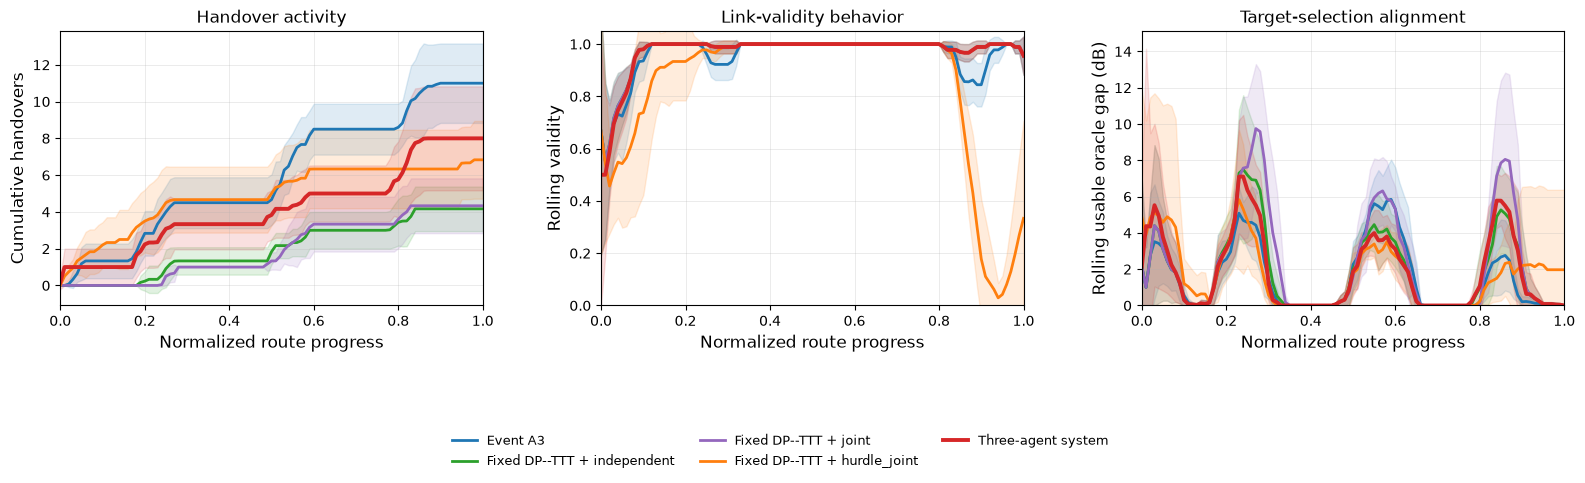

Saved:
/home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/robust_route_progress_curves_clean.pdf
/home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/robust_route_progress_curves_clean.png


In [16]:
# Cell 15 — Route-progress curves across the six LOTO folds

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def enrich_trajectory_metrics(
    trajectory_df,
    fold,
    rolling_window=15,
):
    """
    Add validity, usable oracle gap, cumulative handovers,
    and rolling metrics to a policy trajectory.
    """
    df = trajectory_df.copy().reset_index(drop=True)

    valid_values = []
    gap_values = []
    selected_power_values = []

    for epoch_index, row in df.iterrows():
        selected_index = int(
            row["serving_after"]
        )

        target_db = fold[
            "test_target_db"
        ][epoch_index, 0, :]

        validity = fold[
            "test_Yv"
        ][epoch_index, 0, :].astype(bool)

        selected_valid = bool(
            validity[selected_index]
        )

        valid_values.append(
            float(selected_valid)
        )

        if selected_valid:
            selected_power = float(
                target_db[selected_index]
            )
            oracle_power = float(
                np.max(target_db[validity])
            )

            selected_power_values.append(
                selected_power
            )
            gap_values.append(
                oracle_power - selected_power
            )
        else:
            selected_power_values.append(np.nan)
            gap_values.append(np.nan)

    df["selected_valid"] = valid_values
    df["usable_oracle_gap_db"] = gap_values
    df["selected_power_valid_db"] = (
        selected_power_values
    )

    df["cumulative_handovers"] = (
        df["handover"].cumsum()
    )

    df["rolling_validity"] = (
        df["selected_valid"]
        .rolling(
            rolling_window,
            min_periods=1,
        )
        .mean()
    )

    df["rolling_oracle_gap_db"] = (
        df["usable_oracle_gap_db"]
        .rolling(
            rolling_window,
            min_periods=1,
        )
        .mean()
    )

    df["progress"] = np.linspace(
        0.0,
        1.0,
        len(df),
    )

    return df


# Construct enriched trajectories for every method
method_trajectories = {}

for baseline_name, fold_runs in baseline_runs.items():
    method_trajectories[baseline_name] = []

    for fold_index, result in enumerate(fold_runs):
        enriched = enrich_trajectory_metrics(
            trajectory_df=result["trajectory"],
            fold=fold_data[fold_index],
        )

        enriched["fold"] = fold_index
        enriched["method"] = baseline_name

        method_trajectories[
            baseline_name
        ].append(enriched)

# Add robust three-agent trajectories
method_trajectories["Three-agent system"] = []

for fold_index, fold_run in (
    all_three_agent_runs.items()
):
    enriched = enrich_trajectory_metrics(
        trajectory_df=fold_run["trajectory"],
        fold=fold_data[fold_index],
    )

    enriched["fold"] = fold_index
    enriched["method"] = "Three-agent system"

    method_trajectories[
        "Three-agent system"
    ].append(enriched)


def interpolate_metric(
    fold_frames,
    metric,
    grid,
):
    """
    Interpolate one metric for each fold onto
    a common normalized route-progress grid.
    """
    interpolated = []

    for df in fold_frames:
        x = df["progress"].to_numpy()
        y = df[metric].to_numpy()

        valid = np.isfinite(y)

        if valid.sum() < 2:
            interpolated.append(
                np.full_like(grid, np.nan)
            )
            continue

        interpolated.append(
            np.interp(
                grid,
                x[valid],
                y[valid],
            )
        )

    return np.asarray(interpolated)


def plot_mean_std_curve(
    ax,
    metric,
    ylabel,
    title,
    methods,
    grid,
):
    colors = {
        "Event A3": "#1f77b4",
        "Fixed DP--TTT + independent": "#2ca02c",
        "Fixed DP--TTT + joint": "#9467bd",
        "Fixed DP--TTT + hurdle_joint": "#ff7f0e",
        "Three-agent system": "#d62728",
    }

    for method in methods:
        curves = interpolate_metric(
            method_trajectories[method],
            metric,
            grid,
        )

        mean_curve = np.nanmean(
            curves,
            axis=0,
        )

        std_curve = np.nanstd(
            curves,
            axis=0,
        )

        color = colors[method]

        ax.plot(
            grid,
            mean_curve,
            label=method,
            color=color,
            linewidth=2.0,
        )

        ax.fill_between(
            grid,
            mean_curve - std_curve,
            mean_curve + std_curve,
            color=color,
            alpha=0.14,
        )

    ax.set_xlabel("Normalized route progress")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(
        True,
        alpha=0.25,
        linewidth=0.7,
    )
    ax.set_xlim(0.0, 1.0)


plot_methods = [
    "Event A3",
    "Fixed DP--TTT + independent",
    "Fixed DP--TTT + joint",
    "Fixed DP--TTT + hurdle_joint",
    "Three-agent system",
]

progress_grid = np.linspace(
    0.0,
    1.0,
    101,
)

# Improved figure layout

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.5),
    constrained_layout=False,
)

plot_mean_std_curve(
    ax=axes[0],
    metric="cumulative_handovers",
    ylabel="Cumulative handovers",
    title="Handover activity",
    methods=plot_methods,
    grid=progress_grid,
)

plot_mean_std_curve(
    ax=axes[1],
    metric="rolling_validity",
    ylabel="Rolling validity",
    title="Link-validity behavior",
    methods=plot_methods,
    grid=progress_grid,
)

plot_mean_std_curve(
    ax=axes[2],
    metric="rolling_oracle_gap_db",
    ylabel="Rolling usable oracle gap (dB)",
    title="Target-selection alignment",
    methods=plot_methods,
    grid=progress_grid,
)

# Improve axis limits
axes[1].set_ylim(0.0, 1.05)
axes[2].set_ylim(bottom=0.0)

for ax in axes:
    ax.set_xlabel("Normalized route progress")
    ax.grid(True, alpha=0.25, linewidth=0.7)

# Highlight the proposed method
for ax in axes:
    for line in ax.lines:
        if line.get_label() == "Three-agent system":
            line.set_linewidth(2.8)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01),
)

fig.subplots_adjust(
    left=0.05,
    right=0.99,
    top=0.88,
    bottom=0.27,
    wspace=0.28,
)

figures_path = (
    FIGURES_DIR / "robust_route_progress_curves_clean.pdf"
)

figures_png_path = (
    FIGURES_DIR / "robust_route_progress_curves_clean.png"
)

fig.savefig(
    figures_path,
    bbox_inches="tight",
)

fig.savefig(
    figures_png_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved:\n{figures_path}")
print(figures_png_path)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

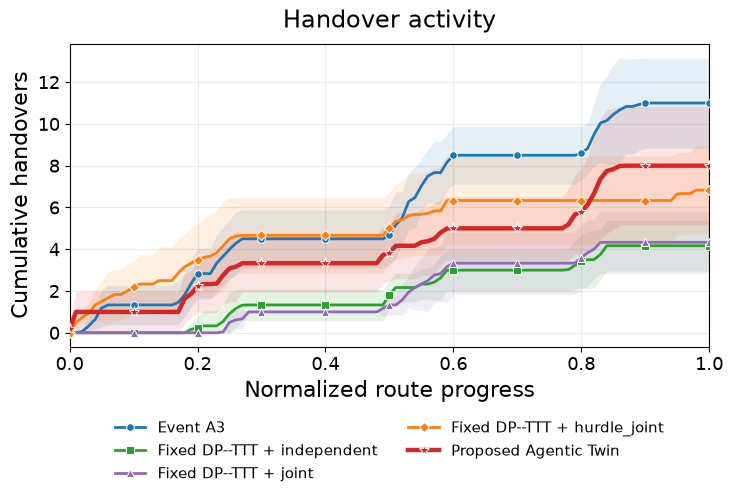

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_handover_activity.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_handover_activity.png


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

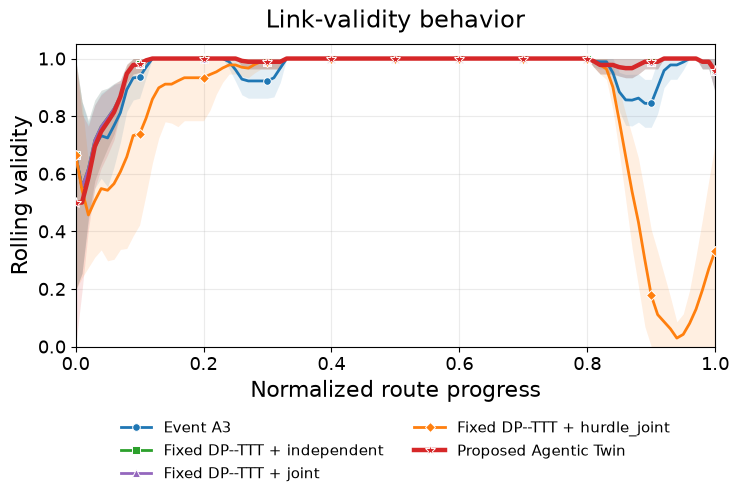

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_link_validity.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_link_validity.png


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

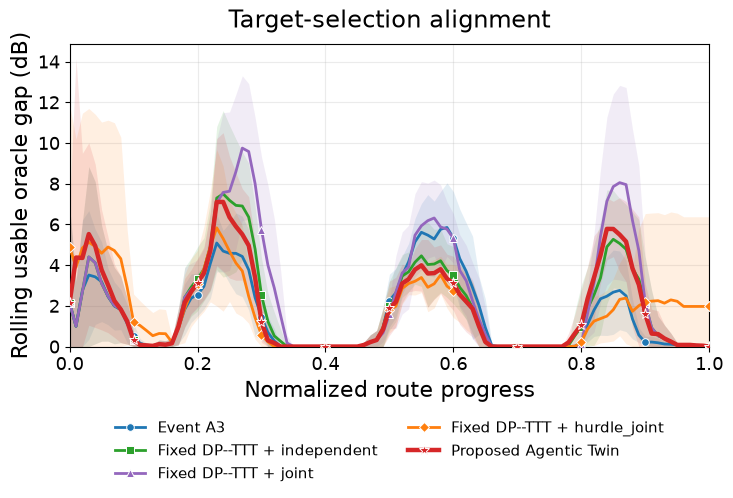

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_target_alignment.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_target_alignment.png


In [18]:
# Cell 16 — Replot using the name "Proposed Agentic Twin"

PROPOSED_NAME = "Proposed Agentic Twin"

# Rename the trajectory entry
if "Three-agent system" in method_trajectories:
    method_trajectories[PROPOSED_NAME] = (
        method_trajectories.pop("Three-agent system")
    )

plot_methods_agentic = [
    "Event A3",
    "Fixed DP--TTT + independent",
    "Fixed DP--TTT + joint",
    "Fixed DP--TTT + hurdle_joint",
    PROPOSED_NAME,
]

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.titlesize": 17,
    "legend.fontsize": 11,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

colors = {
    "Event A3": "#1f77b4",
    "Fixed DP--TTT + independent": "#2ca02c",
    "Fixed DP--TTT + joint": "#9467bd",
    "Fixed DP--TTT + hurdle_joint": "#ff7f0e",
    PROPOSED_NAME: "#d62728",
}

markers = {
    "Event A3": "o",
    "Fixed DP--TTT + independent": "s",
    "Fixed DP--TTT + joint": "^",
    "Fixed DP--TTT + hurdle_joint": "D",
    PROPOSED_NAME: "*",
}

curve_specs = [
    {
        "metric": "cumulative_handovers",
        "ylabel": "Cumulative handovers",
        "title": "Handover activity",
        "filename": "proposed_agentic_twin_handover_activity",
        "ylim": None,
    },
    {
        "metric": "rolling_validity",
        "ylabel": "Rolling validity",
        "title": "Link-validity behavior",
        "filename": "proposed_agentic_twin_link_validity",
        "ylim": (0.0, 1.05),
    },
    {
        "metric": "rolling_oracle_gap_db",
        "ylabel": "Rolling usable oracle gap (dB)",
        "title": "Target-selection alignment",
        "filename": "proposed_agentic_twin_target_alignment",
        "ylim": (0.0, None),
    },
]

marker_positions = np.linspace(
    0,
    len(progress_grid) - 1,
    11,
).astype(int)

for spec in curve_specs:
    fig, ax = plt.subplots(
        figsize=(7.8, 5.4),
        constrained_layout=False,
    )

    for method in plot_methods_agentic:
        curves = interpolate_metric(
            method_trajectories[method],
            spec["metric"],
            progress_grid,
        )

        mean_curve = np.nanmean(
            curves,
            axis=0,
        )

        std_curve = np.nanstd(
            curves,
            axis=0,
        )

        lower_curve = np.maximum(
            mean_curve - std_curve,
            0.0,
        )

        upper_curve = mean_curve + std_curve

        if spec["metric"] == "rolling_validity":
            upper_curve = np.minimum(
                upper_curve,
                1.0,
            )

        is_proposed = method == PROPOSED_NAME

        ax.plot(
            progress_grid,
            mean_curve,
            color=colors[method],
            linewidth=3.2 if is_proposed else 2.0,
            marker=markers[method],
            markersize=8 if is_proposed else 5.5,
            markevery=marker_positions.tolist(),
            markeredgecolor="white",
            markeredgewidth=0.7,
            label=method,
            zorder=4 if is_proposed else 3,
        )

        ax.fill_between(
            progress_grid,
            lower_curve,
            upper_curve,
            color=colors[method],
            alpha=0.12,
            linewidth=0,
            zorder=1,
        )

    ax.set_xlabel("Normalized route progress")
    ax.set_ylabel(spec["ylabel"])
    ax.set_title(spec["title"], pad=12)
    ax.set_xlim(0.0, 1.0)

    if spec["ylim"] is not None:
        ax.set_ylim(*spec["ylim"])

    ax.grid(
        True,
        alpha=0.25,
        linewidth=0.8,
    )
    ax.set_axisbelow(True)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
    )

    fig.subplots_adjust(
        left=0.15,
        right=0.97,
        top=0.88,
        bottom=0.32,
    )

    pdf_path = FIGURES_DIR / f"{spec['filename']}.pdf"
    png_path = FIGURES_DIR / f"{spec['filename']}.png"

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
    )

    fig.savefig(
        png_path,
        dpi=400,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved PDF: {pdf_path}")
    print(f"Saved PNG: {png_path}")

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

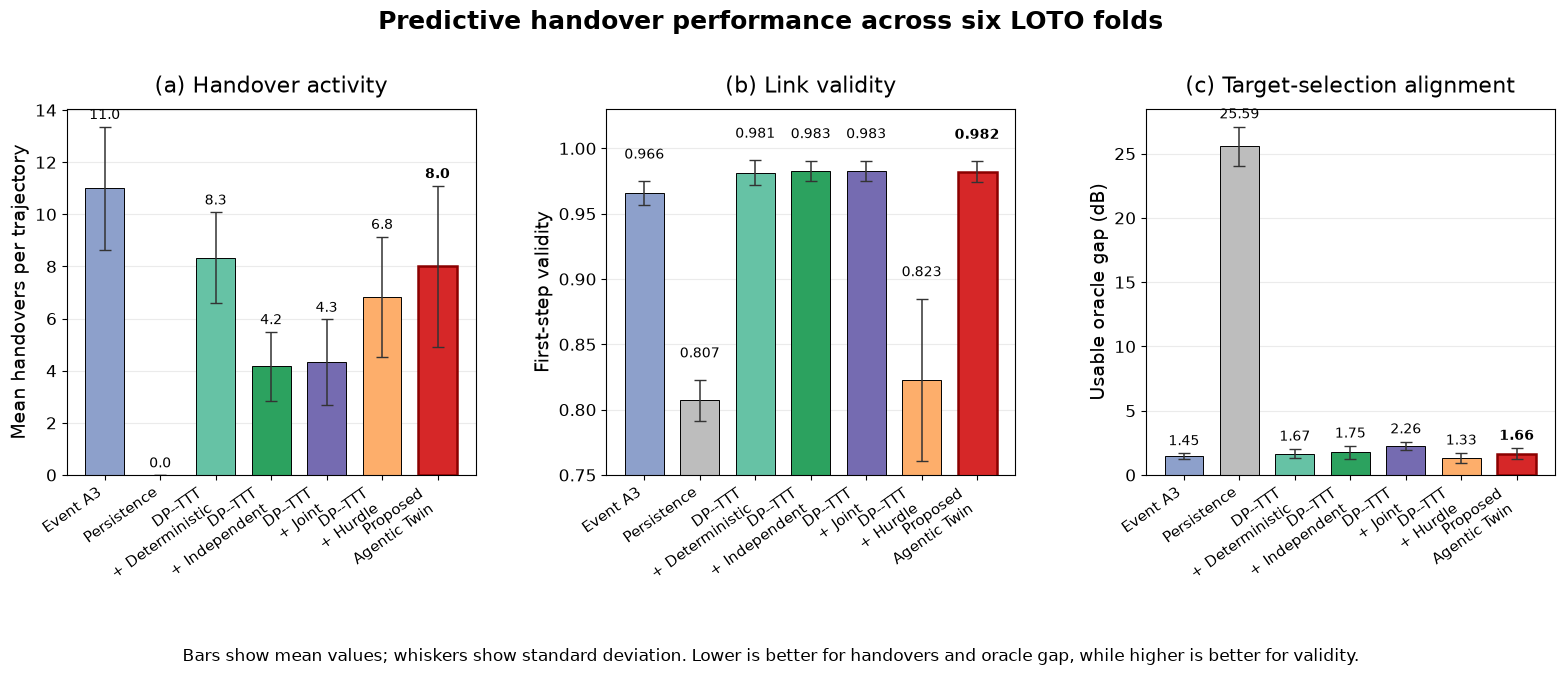

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_bar_balance.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_bar_balance.png


In [21]:
# Cell 17 — Clear bar-plot comparison

import textwrap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROPOSED_NAME = "Proposed Agentic Twin"

bar_df = comparison_summary_df.copy()
bar_df["method"] = bar_df["method"].astype(str)

bar_df["method"] = bar_df["method"].replace({
    "Three-agent system": PROPOSED_NAME
})

# Remove duplicate persistence policy
bar_df = bar_df[
    bar_df["method"] != "Fixed DP--TTT + persistence"
].copy()

method_order = [
    "Event A3",
    "Persistence",
    "Fixed DP--TTT + deterministic",
    "Fixed DP--TTT + independent",
    "Fixed DP--TTT + joint",
    "Fixed DP--TTT + hurdle_joint",
    PROPOSED_NAME,
]

bar_df["method"] = pd.Categorical(
    bar_df["method"],
    categories=method_order,
    ordered=True,
)

bar_df = (
    bar_df
    .sort_values("method")
    .reset_index(drop=True)
)

short_labels = [
    "Event A3",
    "Persistence",
    "DP--TTT\n+ Deterministic",
    "DP--TTT\n+ Independent",
    "DP--TTT\n+ Joint",
    "DP--TTT\n+ Hurdle",
    "Proposed\nAgentic Twin",
]

colors = [
    "#8da0cb",
    "#bdbdbd",
    "#66c2a5",
    "#2ca25f",
    "#756bb1",
    "#fdae6b",
    "#d62728",
]

x = np.arange(len(bar_df))
width = 0.70

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 6.2),
)

metrics = [
    {
        "mean": "handovers_mean",
        "std": "handovers_std",
        "ylabel": "Mean handovers per trajectory",
        "title": "(a) Handover activity",
        "lower_better": True,
    },
    {
        "mean": "first_step_validity_mean",
        "std": "first_step_validity_std",
        "ylabel": "First-step validity",
        "title": "(b) Link validity",
        "lower_better": False,
    },
    {
        "mean": "usable_oracle_gap_db_mean",
        "std": "usable_oracle_gap_db_std",
        "ylabel": "Usable oracle gap (dB)",
        "title": "(c) Target-selection alignment",
        "lower_better": True,
    },
]

for ax, metric in zip(axes, metrics):
    means = bar_df[metric["mean"]].to_numpy()
    stds = bar_df[metric["std"]].to_numpy()

    bars = ax.bar(
        x,
        means,
        width=width,
        yerr=stds,
        capsize=4,
        color=colors,
        edgecolor="black",
        linewidth=0.7,
        error_kw={
            "elinewidth": 1.1,
            "ecolor": "#333333",
        },
    )

    # Emphasize Proposed Agentic Twin
    bars[-1].set_linewidth(1.8)
    bars[-1].set_edgecolor("#8b0000")

    ax.set_title(
        metric["title"],
        fontsize=16,
        pad=12,
    )

    ax.set_ylabel(
        metric["ylabel"],
        fontsize=14,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        short_labels,
        rotation=35,
        ha="right",
        fontsize=11,
    )

    ax.tick_params(
        axis="y",
        labelsize=12,
    )

    ax.grid(
        axis="y",
        alpha=0.25,
        linewidth=0.8,
    )

    ax.set_axisbelow(True)

    # Add values above bars
    for index, (mean, std) in enumerate(
        zip(means, stds)
    ):
        if metric["mean"] == "first_step_validity_mean":
            label = f"{mean:.3f}"
        elif metric["mean"] == "usable_oracle_gap_db_mean":
            label = f"{mean:.2f}"
        else:
            label = f"{mean:.1f}"

        ax.text(
            index,
            mean + std + 0.015 * max(means),
            label,
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold" if index == len(means) - 1 else "normal",
        )

    if metric["mean"] == "first_step_validity_mean":
        ax.set_ylim(0.75, 1.03)

fig.suptitle(
    "Predictive handover performance across six LOTO folds",
    fontsize=18,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.5,
    -0.03,
    "Bars show mean values; whiskers show standard deviation. "
    "Lower is better for handovers and oracle gap, while higher is better for validity.",
    ha="center",
    fontsize=12,
)

fig.subplots_adjust(
    left=0.06,
    right=0.99,
    top=0.86,
    bottom=0.27,
    wspace=0.32,
)

bar_pdf = (
    FIGURES_DIR
    / "proposed_agentic_twin_bar_balance.pdf"
)

bar_png = (
    FIGURES_DIR
    / "proposed_agentic_twin_bar_balance.png"
)

fig.savefig(
    bar_pdf,
    bbox_inches="tight",
)

fig.savefig(
    bar_png,
    dpi=400,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(f"Saved PDF: {bar_pdf}")
print(f"Saved PNG: {bar_png}")

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

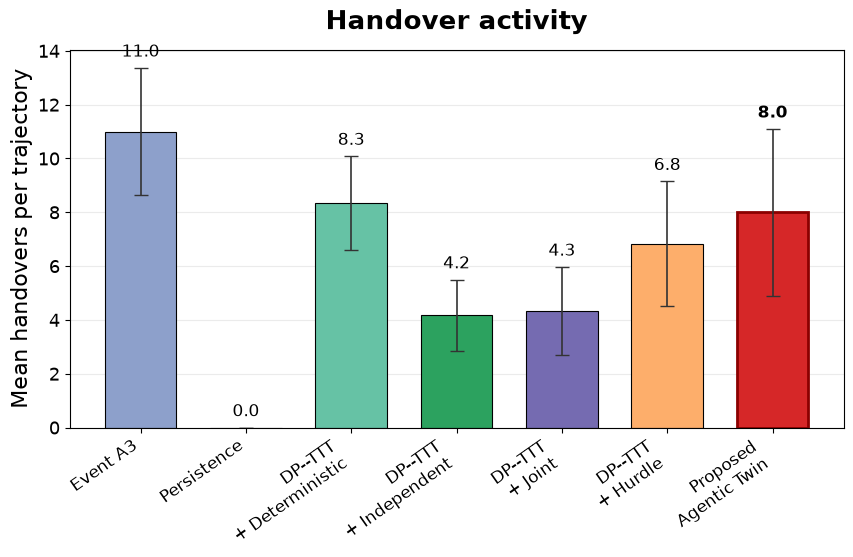

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_handovers.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_handovers.png


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

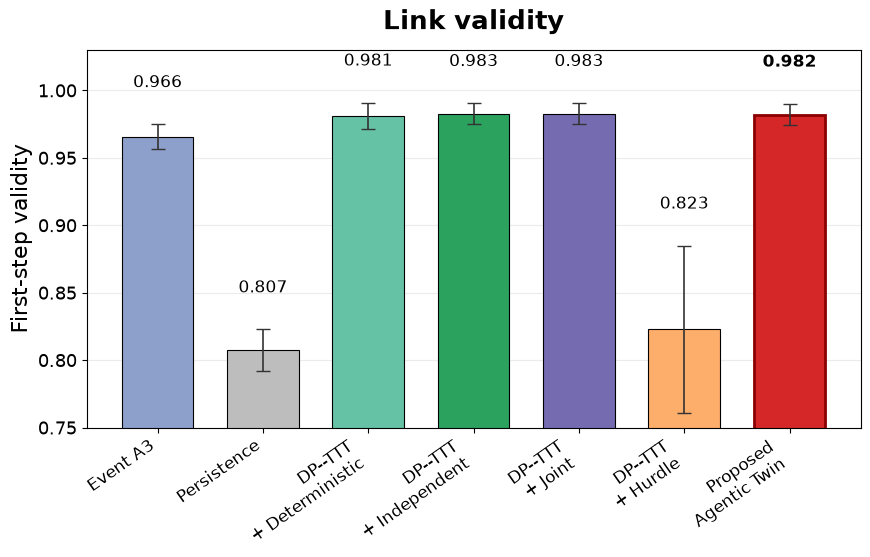

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_validity.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_validity.png


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

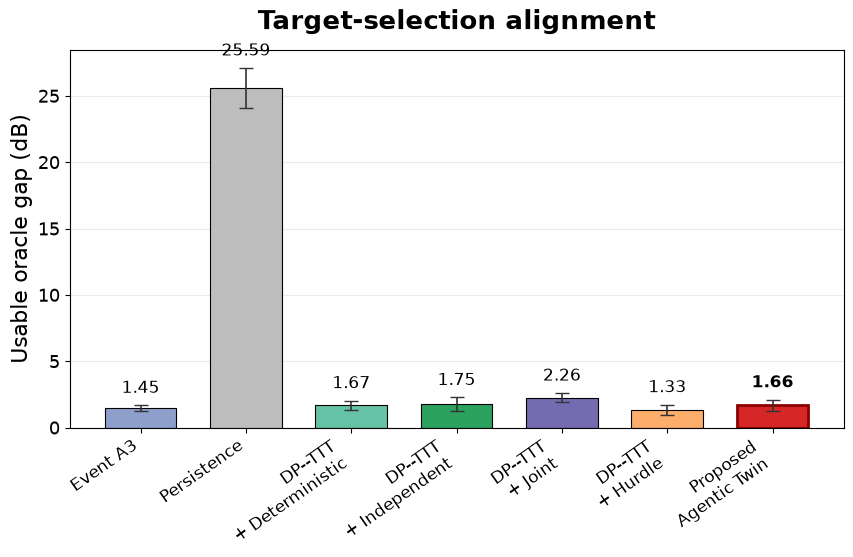

Saved PDF: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_oracle_gap.pdf
Saved PNG: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents_robust/proposed_agentic_twin_oracle_gap.png


In [23]:
# Cell 18 — Save each bar plot as a separate PDF

import matplotlib.pyplot as plt
import numpy as np

separate_bar_specs = [
    {
        "mean": "handovers_mean",
        "std": "handovers_std",
        "ylabel": "Mean handovers per trajectory",
        "title": "Handover activity",
        "filename": "proposed_agentic_twin_handovers",
        "ylim": None,
    },
    {
        "mean": "first_step_validity_mean",
        "std": "first_step_validity_std",
        "ylabel": "First-step validity",
        "title": "Link validity",
        "filename": "proposed_agentic_twin_validity",
        "ylim": (0.75, 1.03),
    },
    {
        "mean": "usable_oracle_gap_db_mean",
        "std": "usable_oracle_gap_db_std",
        "ylabel": "Usable oracle gap (dB)",
        "title": "Target-selection alignment",
        "filename": "proposed_agentic_twin_oracle_gap",
        "ylim": None,
    },
]

for spec in separate_bar_specs:
    means = bar_df[spec["mean"]].to_numpy()
    stds = bar_df[spec["std"]].to_numpy()

    fig, ax = plt.subplots(
        figsize=(9.0, 6.4)
    )

    bars = ax.bar(
        x,
        means,
        width=0.68,
        yerr=stds,
        capsize=5,
        color=colors,
        edgecolor="black",
        linewidth=0.8,
        error_kw={
            "elinewidth": 1.2,
            "ecolor": "#333333",
        },
    )

    # Highlight Proposed Agentic Twin
    bars[-1].set_linewidth(2.0)
    bars[-1].set_edgecolor("#8b0000")

    ax.set_title(
        spec["title"],
        fontsize=19,
        fontweight="bold",
        pad=15,
    )

    ax.set_ylabel(
        spec["ylabel"],
        fontsize=16,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        short_labels,
        rotation=35,
        ha="right",
        fontsize=12,
    )

    ax.tick_params(
        axis="y",
        labelsize=13,
    )

    if spec["ylim"] is not None:
        ax.set_ylim(*spec["ylim"])

    ax.grid(
        axis="y",
        alpha=0.25,
        linewidth=0.8,
    )

    ax.set_axisbelow(True)

    # Add numerical values
    value_range = max(means) - min(means)
    label_offset = (
        0.025 * max(means)
        if value_range > 0
        else 0.02
    )

    for index, (mean, std) in enumerate(
        zip(means, stds)
    ):
        if spec["mean"] == "first_step_validity_mean":
            label = f"{mean:.3f}"
        elif spec["mean"] == "usable_oracle_gap_db_mean":
            label = f"{mean:.2f}"
        else:
            label = f"{mean:.1f}"

        ax.text(
            index,
            mean + std + label_offset,
            label,
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight=(
                "bold"
                if index == len(means) - 1
                else "normal"
            ),
        )

   
    fig.subplots_adjust(
        left=0.12,
        right=0.98,
        top=0.88,
        bottom=0.29,
    )

    pdf_path = (
        FIGURES_DIR
        / f"{spec['filename']}.pdf"
    )

    png_path = (
        FIGURES_DIR
        / f"{spec['filename']}.png"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
    )

    fig.savefig(
        png_path,
        dpi=400,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved PDF: {pdf_path}")
    print(f"Saved PNG: {png_path}")

In [24]:
# Cell 19 — Runtime-complexity comparison

import time
import gc

RUNTIME_REPEATS = 3
runtime_records = []

runtime_methods = [
    ("Event A3", None),
    ("Persistence", None),
    ("Fixed DP--TTT + deterministic", "deterministic"),
    ("Fixed DP--TTT + independent", "independent"),
    ("Fixed DP--TTT + joint", "joint"),
    ("Fixed DP--TTT + hurdle_joint", "hurdle_joint"),
    ("Proposed Agentic Twin", None),
]

for method_name, model_name in runtime_methods:
    print(f"Timing {method_name}...")

    for fold_index, fold in enumerate(fold_data):
        elapsed_times = []

        # Warm-up run
        if method_name == "Proposed Agentic Twin":
            run_three_agent_fold(
                fold=fold,
                fold_index=fold_index,
                initial_serving_index=4,
            )
        else:
            run_baseline_fold(
                fold=fold,
                fold_index=fold_index,
                baseline_name=method_name,
                model_name=model_name,
                initial_serving_index=4,
            )

        # Timed runs
        for _ in range(RUNTIME_REPEATS):
            gc.collect()

            start_time = time.perf_counter()

            if method_name == "Proposed Agentic Twin":
                run_three_agent_fold(
                    fold=fold,
                    fold_index=fold_index,
                    initial_serving_index=4,
                )
            else:
                run_baseline_fold(
                    fold=fold,
                    fold_index=fold_index,
                    baseline_name=method_name,
                    model_name=model_name,
                    initial_serving_index=4,
                )

            elapsed = time.perf_counter() - start_time
            elapsed_times.append(elapsed)

        num_epochs = fold[
            "test_target_db"
        ].shape[0]

        runtime_records.append({
            "method": method_name,
            "fold": fold_index,
            "total_time_s": np.mean(elapsed_times),
            "time_std_s": np.std(elapsed_times),
            "time_per_epoch_ms": (
                1000.0
                * np.mean(elapsed_times)
                / num_epochs
            ),
            "epochs": num_epochs,
        })

runtime_fold_df = pd.DataFrame(runtime_records)

runtime_summary_df = (
    runtime_fold_df
    .groupby("method", as_index=False)
    .agg(
        total_time_mean_s=(
            "total_time_s",
            "mean",
        ),
        total_time_std_s=(
            "total_time_s",
            "std",
        ),
        decision_time_mean_ms=(
            "time_per_epoch_ms",
            "mean",
        ),
        decision_time_std_ms=(
            "time_per_epoch_ms",
            "std",
        ),
    )
)

runtime_summary_df["relative_to_event_a3"] = (
    runtime_summary_df["decision_time_mean_ms"]
    / runtime_summary_df.loc[
        runtime_summary_df["method"] == "Event A3",
        "decision_time_mean_ms",
    ].iloc[0]
)

runtime_summary_df = runtime_summary_df.sort_values(
    "decision_time_mean_ms"
).reset_index(drop=True)

print("\nRuntime comparison:")
display(
    runtime_summary_df.round({
        "total_time_mean_s": 4,
        "total_time_std_s": 4,
        "decision_time_mean_ms": 4,
        "decision_time_std_ms": 4,
        "relative_to_event_a3": 2,
    })
)

# Save CSV
runtime_csv_path = (
    REPORT_DIR / "policy_runtime_complexity.csv"
)

runtime_summary_df.to_csv(
    runtime_csv_path,
    index=False,
)

# Save LaTeX table
runtime_latex_path = (
    REPORT_DIR / "policy_runtime_complexity.tex"
)

runtime_table = runtime_summary_df.copy()
runtime_table.columns = [
    "Method",
    "Total time mean [s]",
    "Total time std [s]",
    "Decision time mean [ms]",
    "Decision time std [ms]",
    "Relative to Event A3",
]

runtime_table.to_latex(
    runtime_latex_path,
    index=False,
    float_format="%.3f",
)

print(f"\nSaved CSV: {runtime_csv_path}")
print(f"Saved LaTeX table: {runtime_latex_path}")

Timing Event A3...
Timing Persistence...
Timing Fixed DP--TTT + deterministic...
Timing Fixed DP--TTT + independent...
Timing Fixed DP--TTT + joint...
Timing Fixed DP--TTT + hurdle_joint...
Timing Proposed Agentic Twin...

Runtime comparison:


,method,total_time_mean_s,total_time_std_s,decision_time_mean_ms,decision_time_std_ms,relative_to_event_a3
0,Persistence,0.0068,0.0003,0.0303,0.0013,0.98
1,Event A3,0.0069,0.0003,0.0311,0.0013,1.00
2,Fixed DP--TTT + deterministic,0.0116,0.0006,0.0519,0.0025,1.67
3,Fixed DP--TTT + independent,0.0129,0.0009,0.0577,0.0041,1.86
4,Fixed DP--TTT + joint,0.0130,0.0008,0.0582,0.0034,1.87
5,Fixed DP--TTT + hurdle_joint,0.0143,0.0007,0.0643,0.0032,2.07
6,Proposed Agentic Twin,1.1422,0.0228,5.1221,0.1022,164.83



Saved CSV: /home/afanali/wcnc_project/improved_experiment_v2/robust_three_agent_results/policy_runtime_complexity.csv
Saved LaTeX table: /home/afanali/wcnc_project/improved_experiment_v2/robust_three_agent_results/policy_runtime_complexity.tex
